<a href="https://colab.research.google.com/github/dguemar/Practica1_Teachable_Machine/blob/main/Practica1_Teachable_Machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CLASIFICADOR DE IMÁGENES CON TEACHABLE --- Daniel Guerrero Martín --- 2ºDAM

# **1. Introducción**

En esta práctica vamos a desarrollar una aplicación web capaz de reconocer y clasificar imágenes mediante un modelo de inteligencia artificial.

Para ello, utilizaremos Teachable Machine, una herramienta de Google que permite entrenar modelos de aprendizaje automático sin necesidad de programarlos desde cero. Crearemos dos categorías de imágenes, entrenaremos el modelo y lo exportaremos para utilizarlo en una aplicación web desarrollada con HTML, CSS y JavaScript.

Una vez integrado el modelo, mejoraremos la aplicación para que tenga un diseño atractivo y adaptable a distintos dispositivos. También incorporaremos diferentes funcionalidades, como el control de la cámara, la configuración de un porcentaje mínimo de coincidencia, un histórico de resultados y la posibilidad de clasificar imágenes subidas desde el ordenador.

Finalmente, documentaremos el proceso y los resultados obtenidos mediante una memoria realizada en Google Colab.

# **2. Creación del proyecto en Teachable Machine**

En esta primera fase vamos a crear el modelo que posteriormente utilizaremos en nuestra aplicación web.
Paso 1. Acceder a Teachable Machine
Entramos en la página oficial:

https://teachablemachine.withgoogle.com/

Una vez dentro, pulsamos el botón "Primeros pasos" en la esquina superior derecha para comenzar a crear un proyecto.

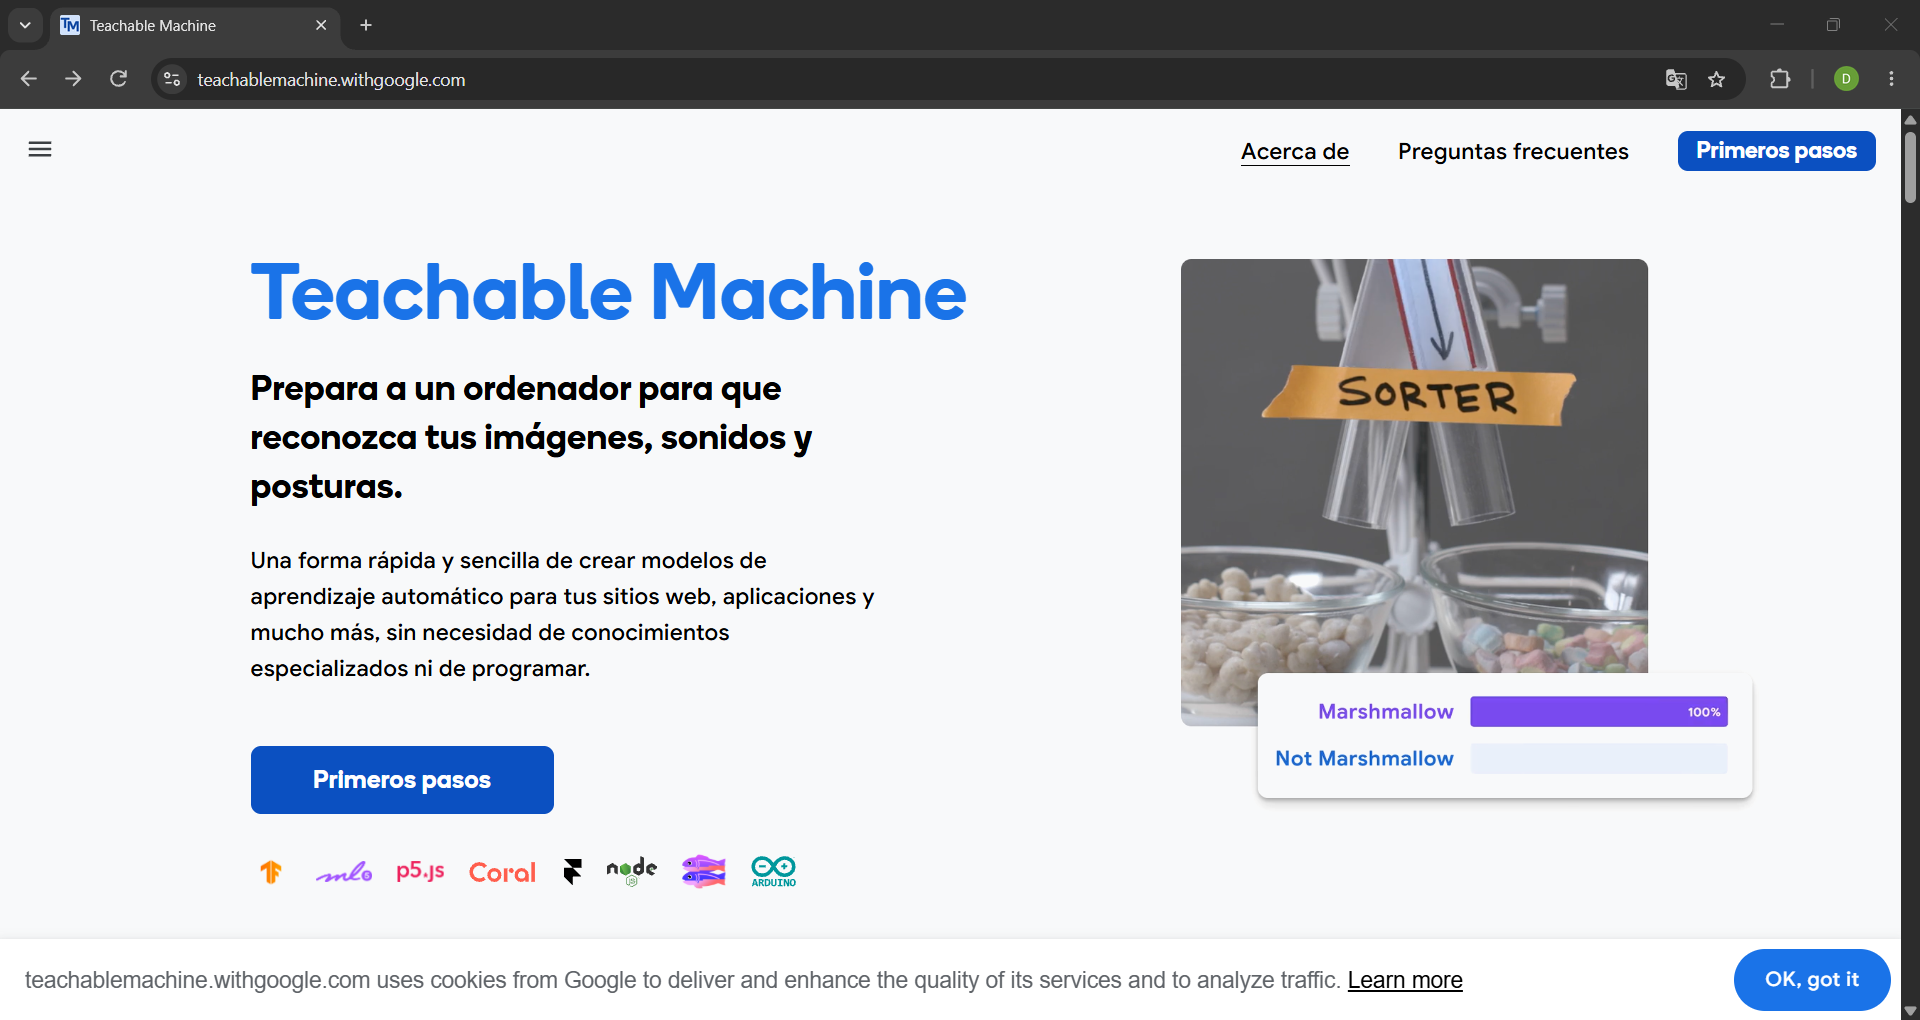

En nuestro caso, seleccionamos la opción Image Project, ya que queremos que la inteligencia artificial reconozca objetos a partir de imágenes.

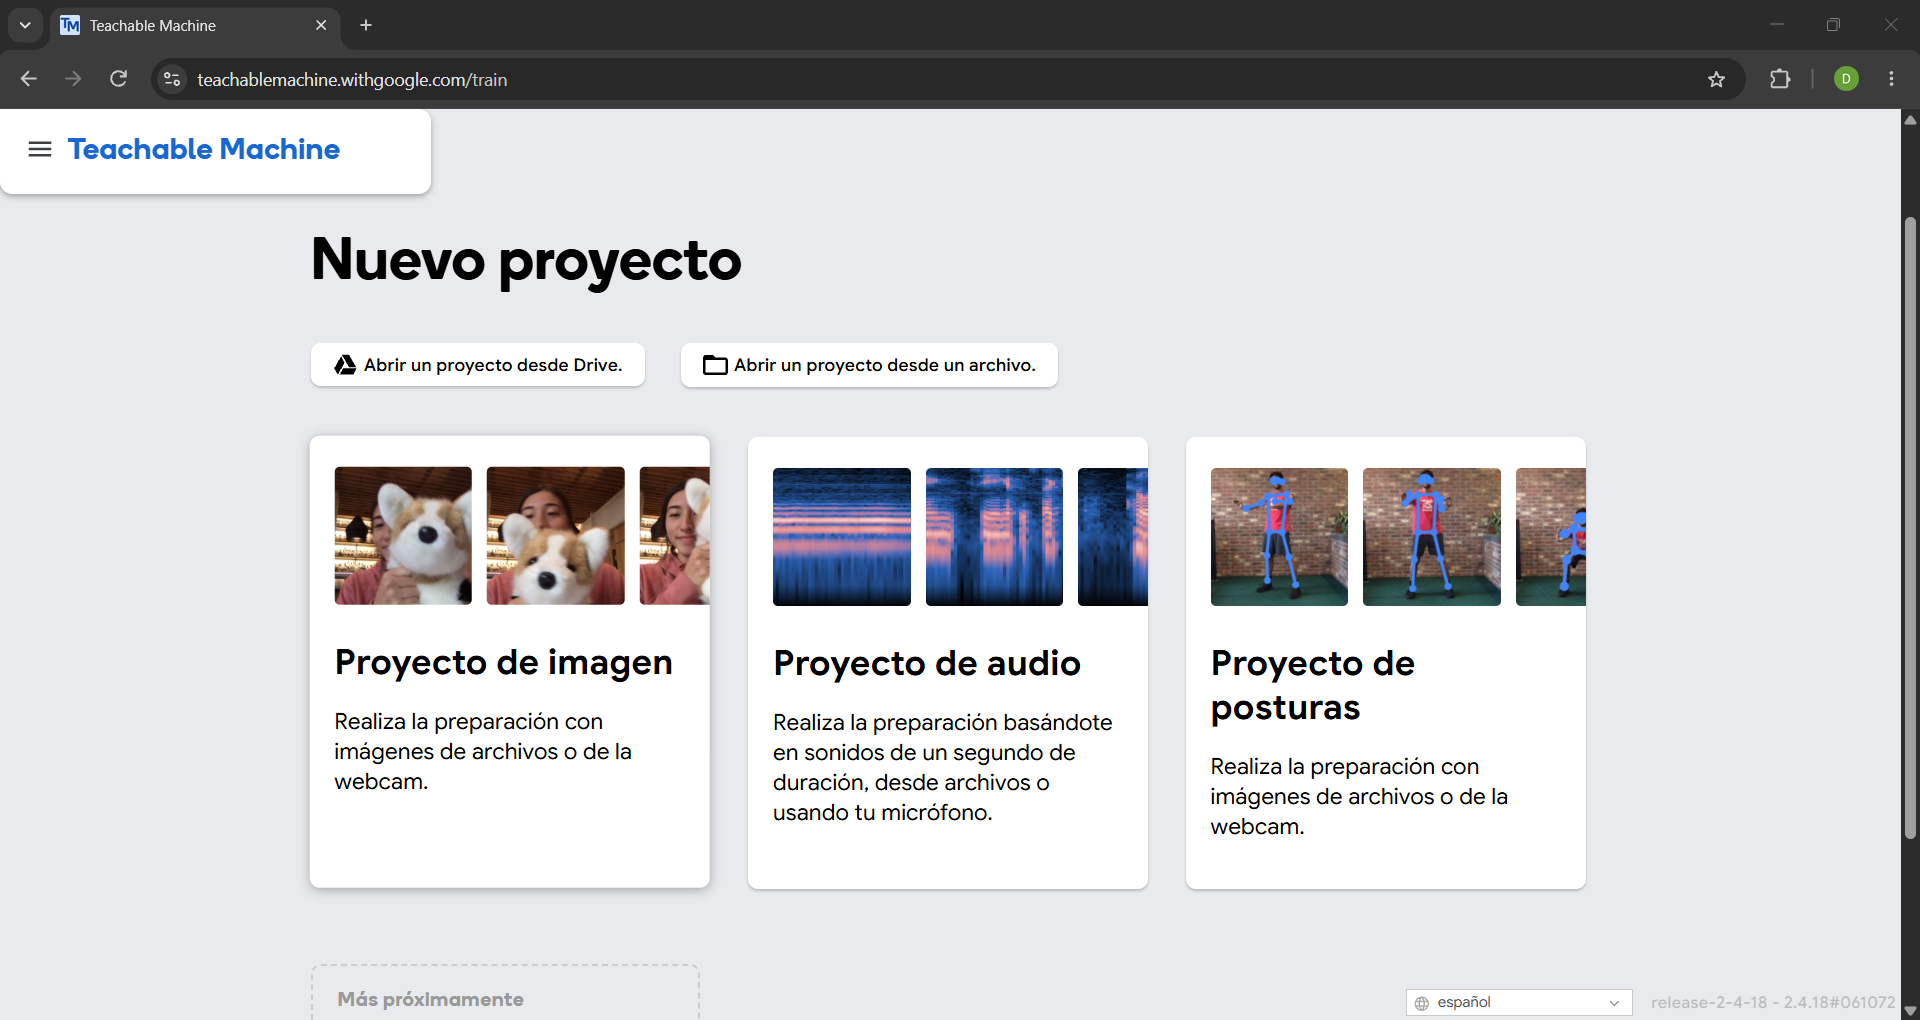

A continuación, elegimos el tipo de proyecto de imágenes estándar, normalmente denominado Standard image model.

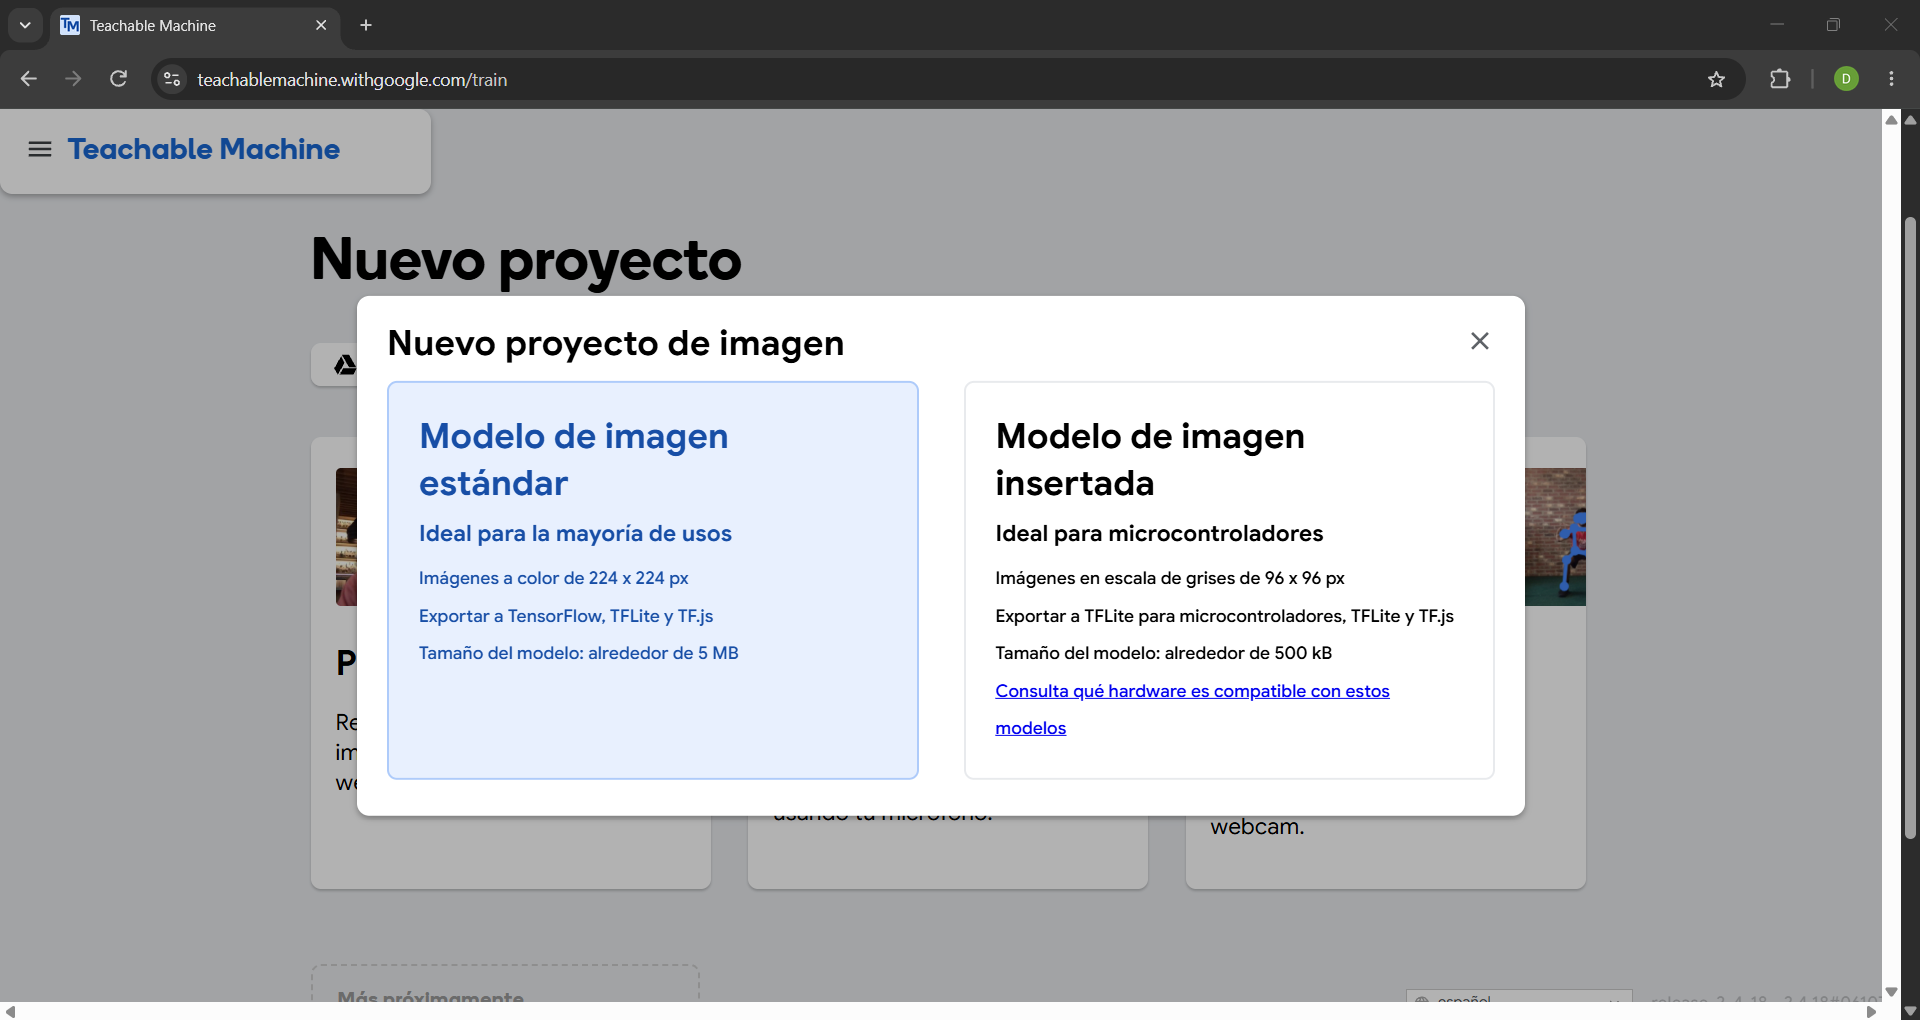

Al abrir el proyecto, aparecerán dos clases iniciales, normalmente llamadas Class 1 y Class 2.

Vamos a cambiar sus nombres para que representen los objetos que queremos reconocer:
- Clase 1: Mando aire acondicionado.
- Clase 2: Pajarita.
Para hacerlo, pulsamos sobre el nombre de cada clase y escribimos el nuevo nombre.

Cada clase representa una categoría diferente que el modelo deberá aprender a distinguir.

Ahora tenemos que proporcionar ejemplos para cada categoría. Teachable Machine permite obtener imágenes utilizando la cámara web o subir imágenes desde el ordenador.

Utilizamos la cámara o subimos fotografías para obtener muestras de cada clase. Es importante incluir imágenes variadas para mejorar el reconocimiento.

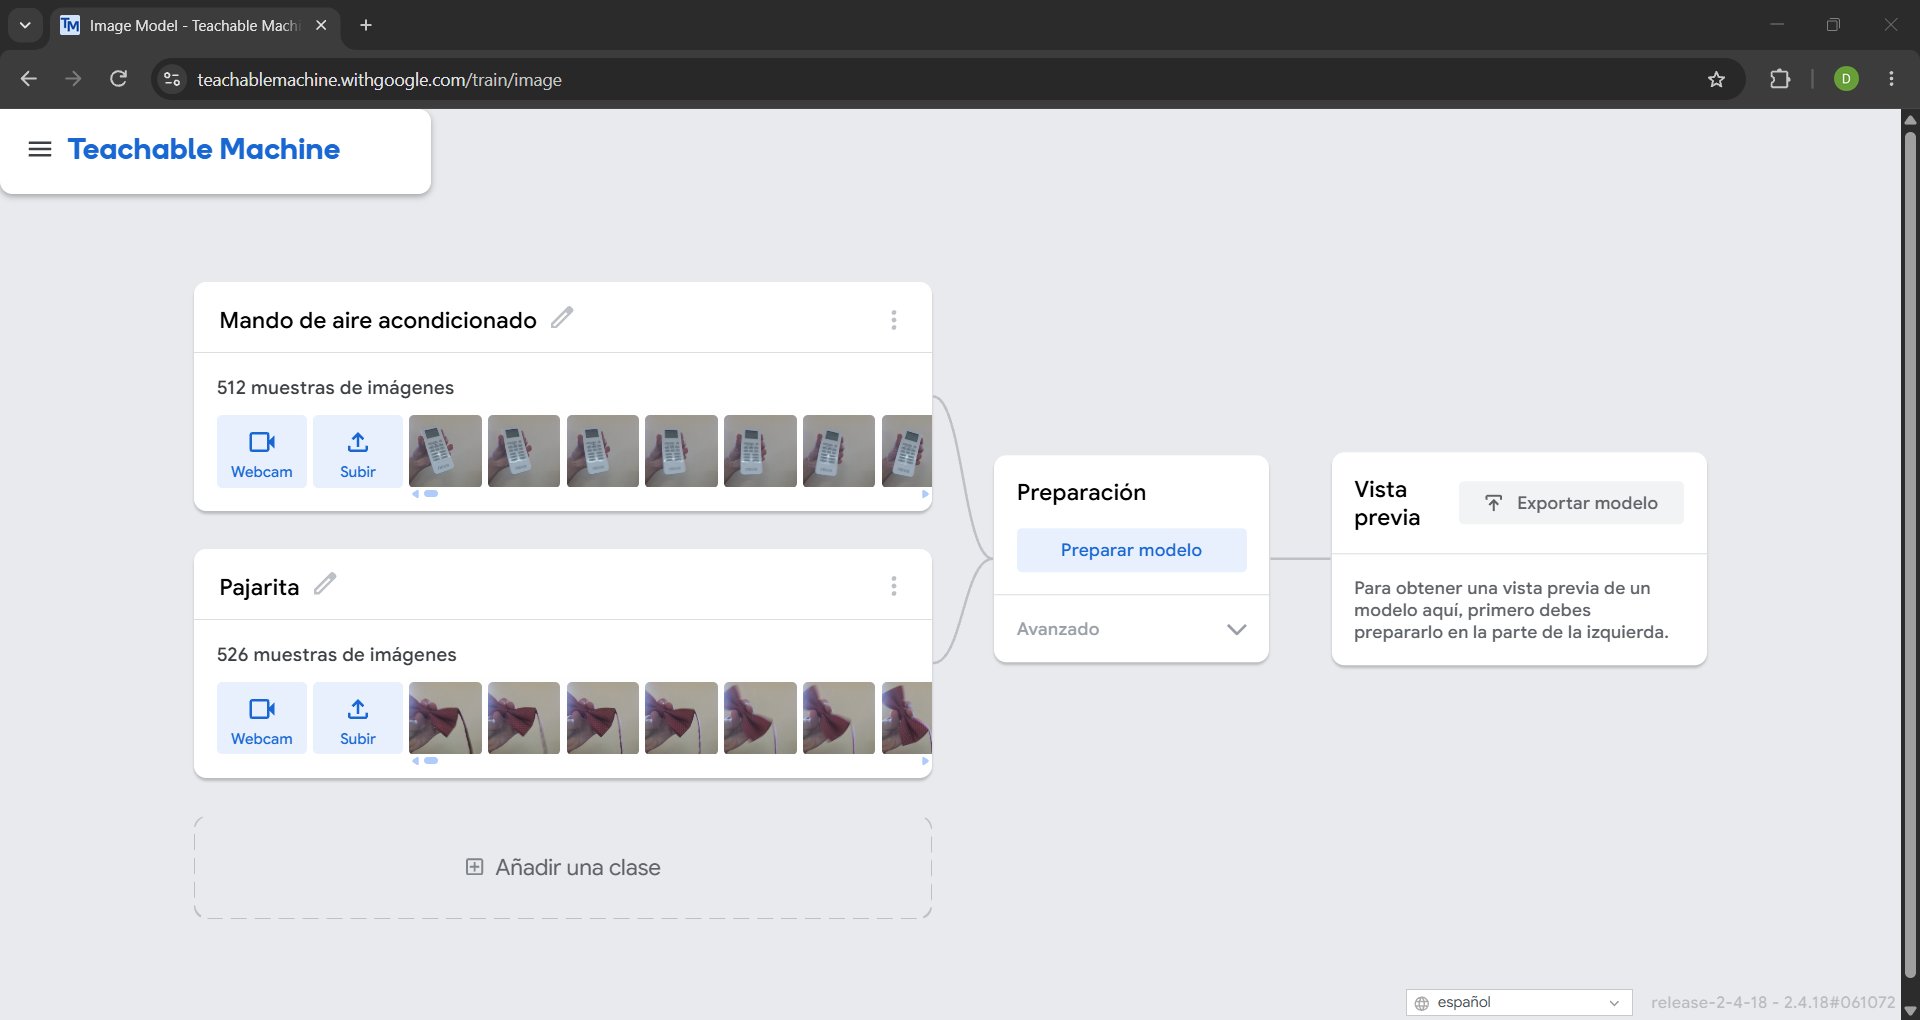



Una vez que hemos recogido las imágenes, pulsamos el botón Train Model.

La herramienta comienza el proceso de aprendizaje automático. Una vez finalizado el entrenamiento probamos el modelo con ambos objetos para comprobar sus predicciones.

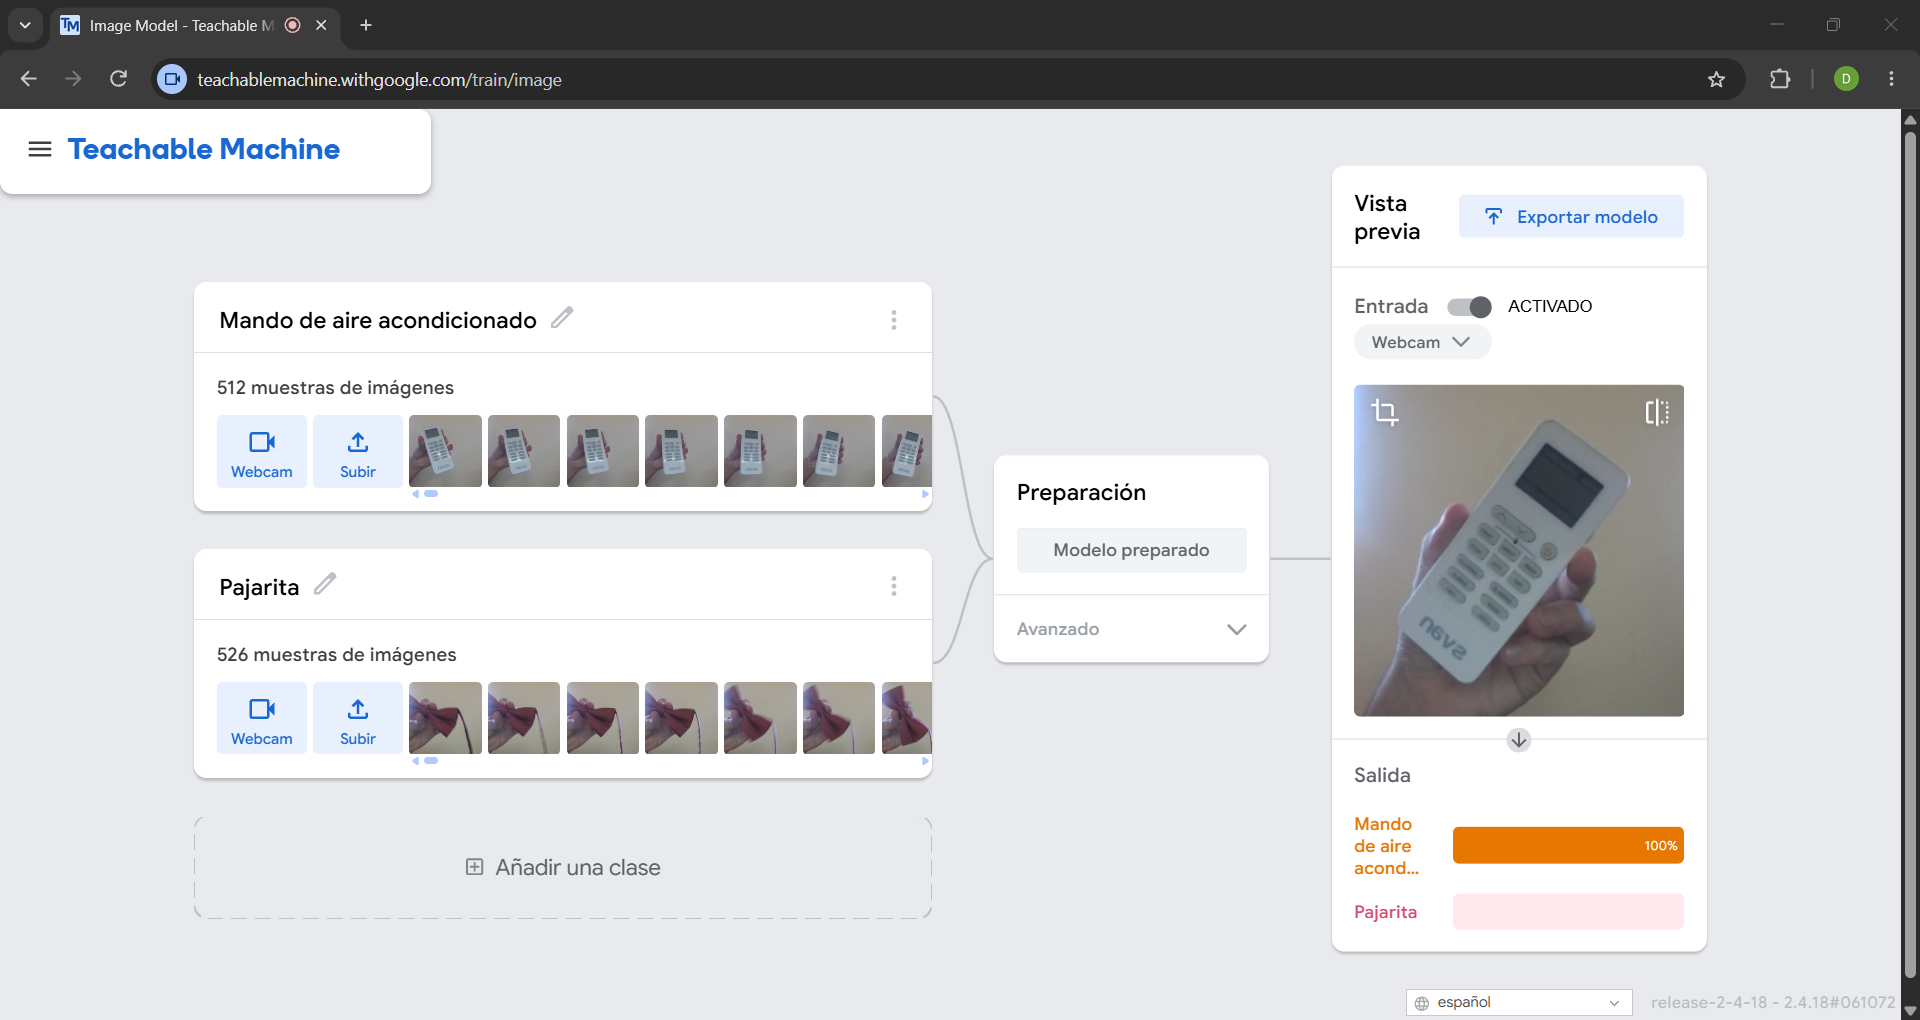

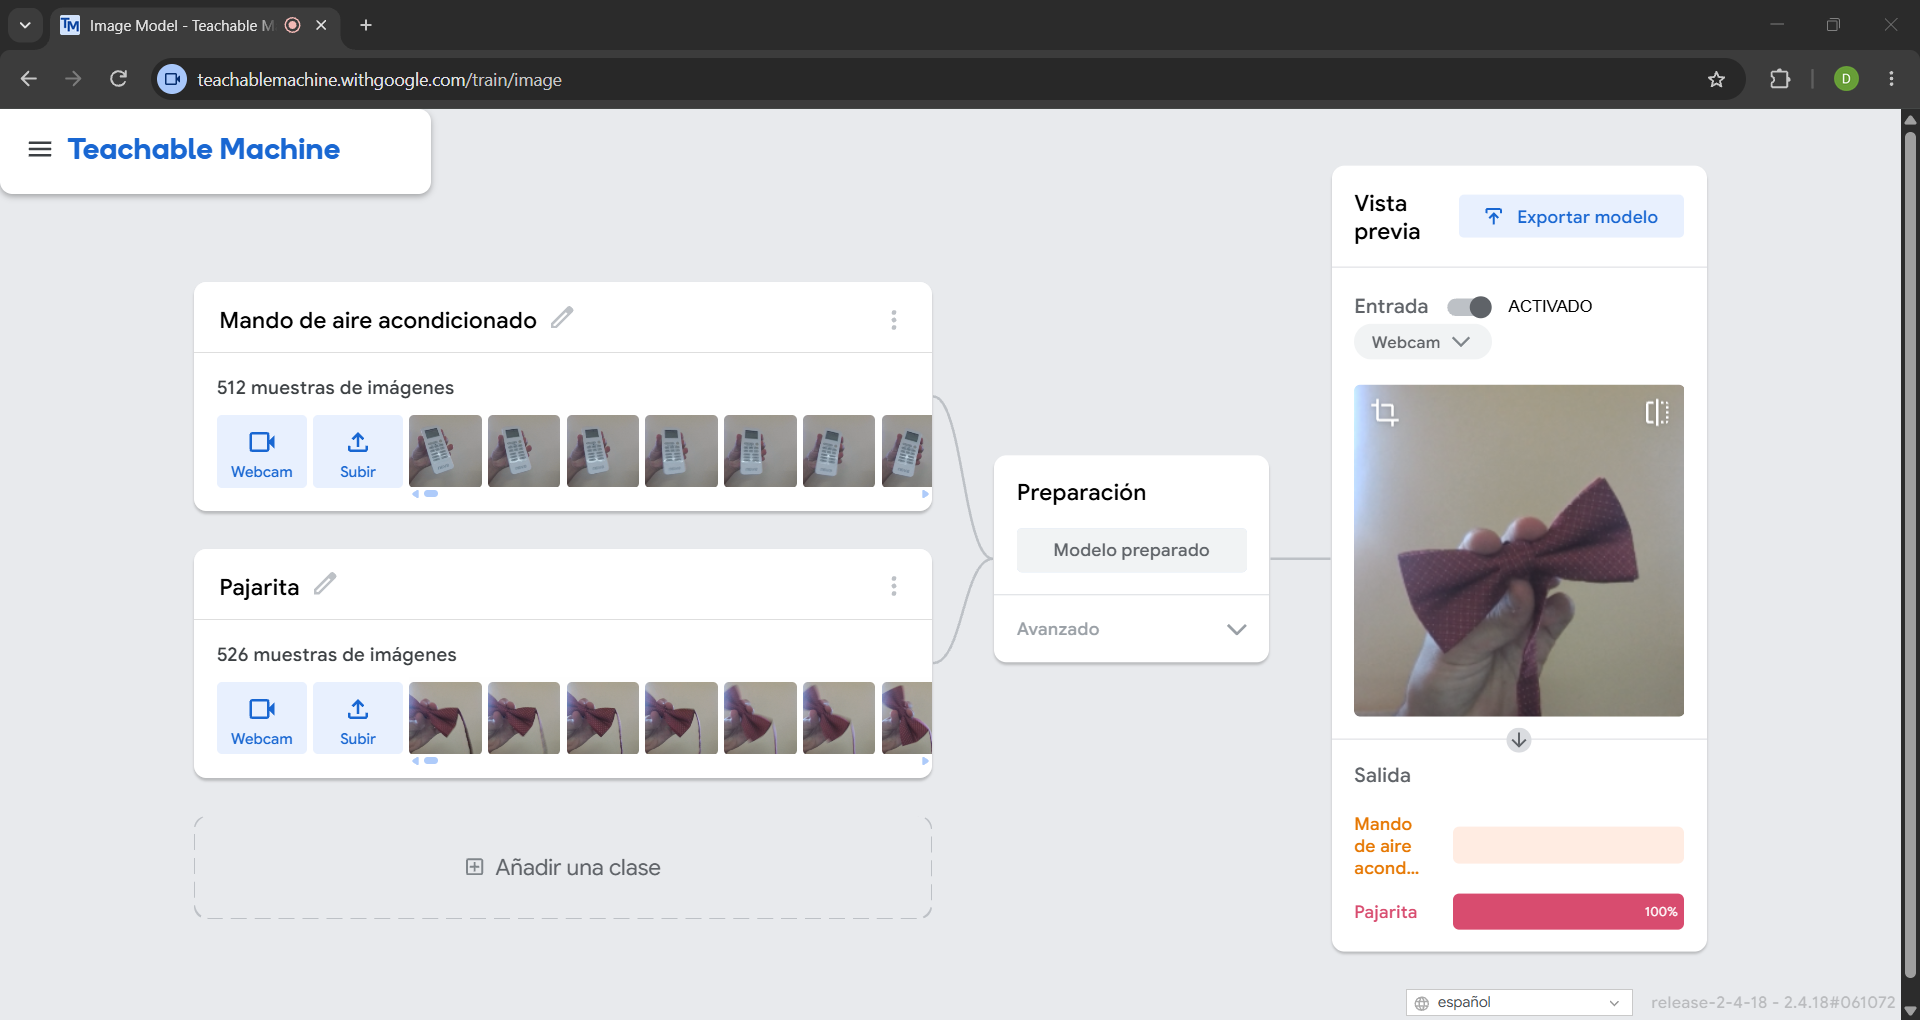

Pulsamos Export Model y descargamos el modelo en dos formatos:
- TensorFlow.js: para utilizarlo en nuestra página web.
- TensorFlow: para conservarlo para una práctica posterior.

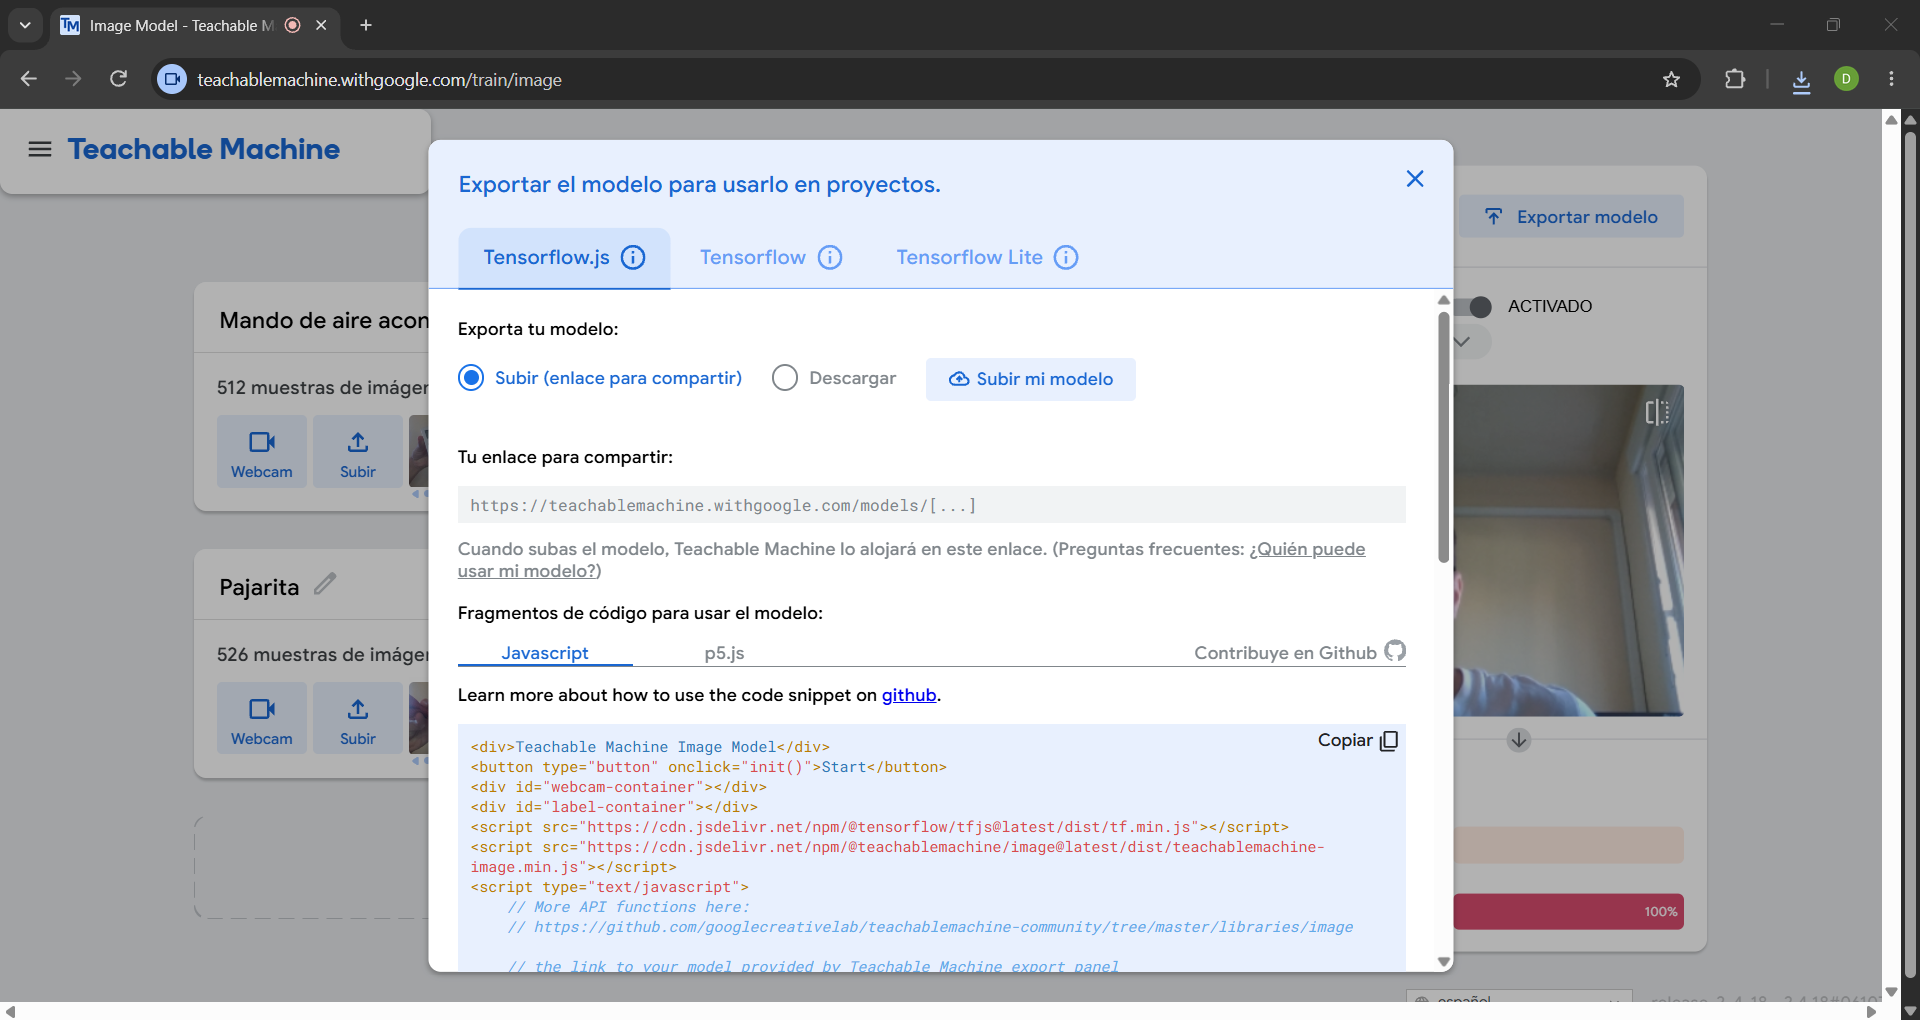

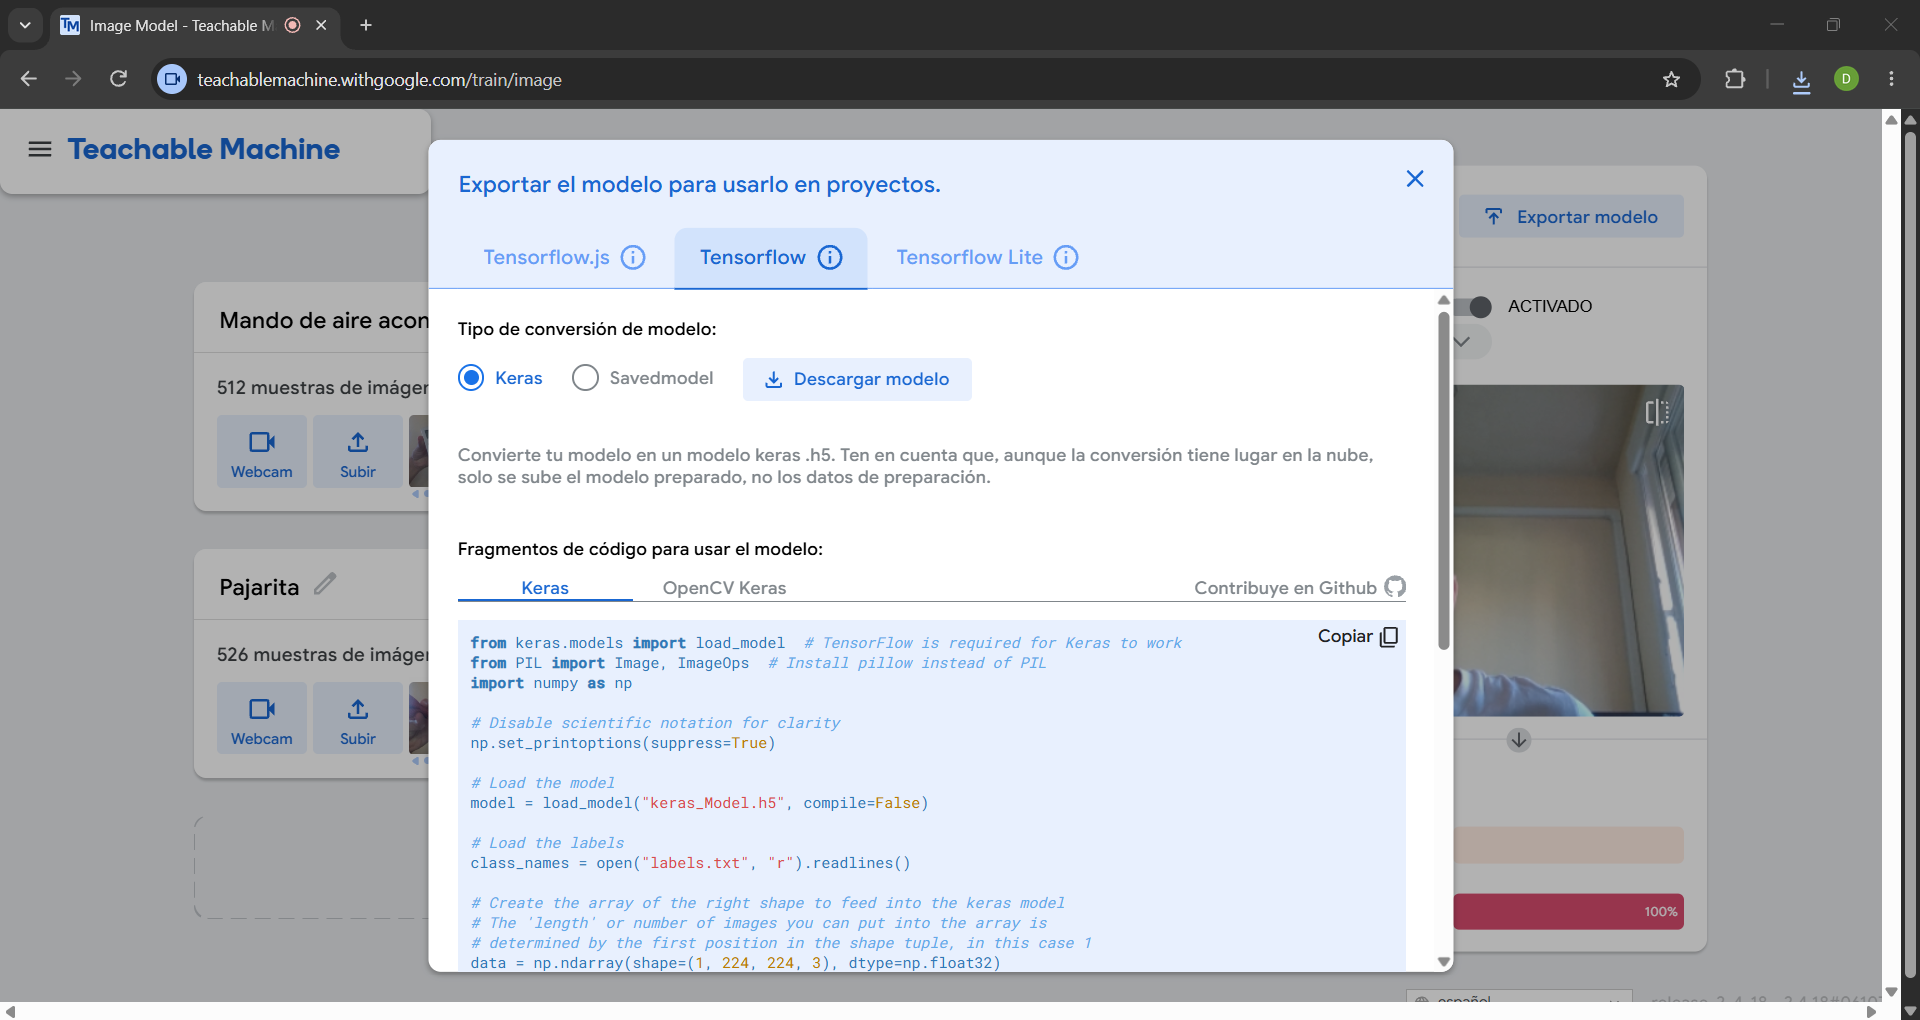

# **3. Desarrollo de la aplicación web**

Creamos la carpeta clasificador con la estructura de la captura.

Cada archivo tiene una función: HTML define la estructura, CSS el diseño, JavaScript controla el funcionamiento y la carpeta modelo contiene el modelo entrenado.

En la carpeta modelo, aparecerán los archivos descomprimidos que hemos exportado desde Teachable Machine.

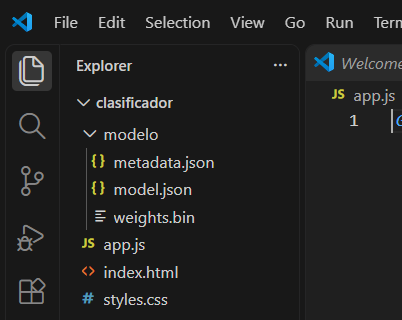

Abrimos una terminal dentro de la carpeta del proyecto y ejecutamos:
python -m http.server 8000


Después accedemos a http://localhost:8000 desde el navegador.

## **Código de index.html**

En index.html creamos los paneles, botones, selector de imágenes y tabla del histórico.

<!DOCTYPE html>
<html lang="es">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <meta name="theme-color" content="#0b1220">
  <title>Clasificador de imágenes con IA</title>
  <link rel="stylesheet" href="./styles.css">
  <script defer src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@latest/dist/tf.min.js"></script>
  <script defer src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8/dist/teachablemachine-image.min.js"></script>
  <script defer src="./app.js"></script>
</head>
<body>
  <header class="site-header">
    <div class="header-content">
      <a class="brand" href="#" aria-label="Clasificador de imágenes con IA, inicio">
        <span class="brand-mark" aria-hidden="true">IA</span>
        <span>Visión inteligente</span>
      </a>
      <span class="header-note">Clasificación de imágenes</span>
    </div>
  </header>

  <main class="page-shell">
    <section class="intro">
      <p class="eyebrow">Daniel Guerrero Martín -- 2º DAM</p>
      <h1>Clasificador de imágenes con IA</h1>
      <p class="intro-copy">Detecta un mando de aire acondicionado o una pajarita usando tu cámara o una imagen de tu dispositivo.</p>
    </section>

    <section class="model-status card" aria-live="polite">
      <span id="modelStatusIcon" class="status-icon is-loading" aria-hidden="true"></span>
      <div>
        <p id="modelStatusTitle" class="status-title">Cargando el modelo…</p>
        <p id="modelStatusMessage" class="status-message">Estamos preparando el clasificador. Puede tardar unos segundos.</p>
      </div>
    </section>

    <div class="tools-grid">
      <section class="card tool-card" aria-labelledby="cameraTitle">
        <div class="card-heading">
          <div>
            <p class="eyebrow">En tiempo real</p>
            <h2 id="cameraTitle">Clasificar con la cámara</h2>
          </div>
          <span class="heading-icon" aria-hidden="true">◉</span>
        </div>
        <p class="section-copy">Activa la cámara y muestra el objeto frente a ella para obtener una predicción en directo.</p>

        <div class="camera-frame">
          <video id="cameraVideo" class="media-preview" autoplay muted playsinline aria-label="Vista previa de la cámara" hidden></video>
          <div id="cameraPlaceholder" class="media-placeholder">
            <span class="placeholder-icon" aria-hidden="true">◎</span>
            <p>La vista de la cámara aparecerá aquí</p>
          </div>
        </div>

        <div class="button-row">
          <button id="startCameraButton" class="button button-primary" type="button" disabled>Iniciar cámara</button>
          <button id="stopCameraButton" class="button button-secondary" type="button" disabled>Detener cámara</button>
        </div>
        <p id="cameraMessage" class="feedback-message" role="status"></p>

        <div class="result-panel" aria-live="polite">
          <div class="result-heading">
            <span class="result-label">Resultado</span>
            <span id="cameraConfidence" class="confidence-value">—</span>
          </div>
          <p id="cameraResult" class="result-class">Esperando una imagen</p>
          <p id="cameraCustomMessage" class="result-description">Inicia la cámara para comenzar a clasificar.</p>
          <div class="confidence-track" aria-hidden="true">
            <span id="cameraConfidenceBar" class="confidence-fill"></span>
          </div>
        </div>
      </section>

      <section class="card tool-card" aria-labelledby="uploadTitle">
        <div class="card-heading">
          <div>
            <p class="eyebrow">Desde tu dispositivo</p>
            <h2 id="uploadTitle">Clasificar una imagen</h2>
          </div>
          <span class="heading-icon upload-icon" aria-hidden="true">↑</span>
        </div>
        <p class="section-copy">Elige una imagen para analizarla con el mismo modelo de Teachable Machine.</p>

        <label class="upload-area" for="imageInput">
          <span class="upload-symbol" aria-hidden="true">＋</span>
          <span class="upload-label">Selecciona una imagen</span>
          <span class="upload-hint">Formatos de imagen habituales</span>
          <input id="imageInput" type="file" accept="image/*">
        </label>

        <div class="image-frame">
          <img id="imagePreview" class="media-preview" alt="Vista previa de la imagen seleccionada" hidden>
          <div id="imagePlaceholder" class="media-placeholder">
            <span class="placeholder-icon" aria-hidden="true">▧</span>
            <p>La imagen seleccionada aparecerá aquí</p>
          </div>
        </div>
        <button id="classifyImageButton" class="button button-primary button-full" type="button" disabled>Clasificar imagen</button>
        <p id="imageMessage" class="feedback-message" role="status"></p>

        <div class="result-panel" aria-live="polite">
          <div class="result-heading">
            <span class="result-label">Resultado</span>
            <span id="imageConfidence" class="confidence-value">—</span>
          </div>
          <p id="imageResult" class="result-class">Esperando una imagen</p>
          <p id="imageCustomMessage" class="result-description">Selecciona una imagen para comenzar.</p>
          <div class="confidence-track" aria-hidden="true">
            <span id="imageConfidenceBar" class="confidence-fill"></span>
          </div>
        </div>
      </section>
    </div>

    <section class="card threshold-card" aria-labelledby="thresholdTitle">
      <div class="threshold-copy">
        <div>
          <p class="eyebrow">Precisión de la predicción</p>
          <h2 id="thresholdTitle">Umbral mínimo de confianza</h2>
        </div>
        <p>Las predicciones por debajo del umbral se mostrarán como no identificadas.</p>
      </div>
      <div class="threshold-control">
        <label for="confidenceThreshold">Confianza mínima</label>
        <div class="range-row">
          <input id="confidenceThreshold" type="range" min="0" max="100" value="60">
          <output id="thresholdValue" for="confidenceThreshold">60 %</output>
        </div>
      </div>
    </section>

    <section class="card history-card" aria-labelledby="historyTitle">
      <div class="history-heading">
        <div>
          <p class="eyebrow">Tus resultados</p>
          <h2 id="historyTitle">Historial de clasificaciones</h2>
        </div>
        <button id="clearHistoryButton" class="button button-quiet" type="button">Borrar historial</button>
      </div>
      <p id="historyMessage" class="feedback-message" role="status"></p>
      <div class="history-table-wrap">
        <table class="history-table">
          <thead>
            <tr>
              <th scope="col">Fecha</th>
              <th scope="col">Clase detectada</th>
              <th scope="col">Confianza</th>
            </tr>
          </thead>
          <tbody id="historyBody">
            <tr class="empty-history">
              <td colspan="3">Todavía no hay clasificaciones guardadas.</td>
            </tr>
          </tbody>
        </table>
      </div>
    </section>
    <footer class="page-footer">Las imágenes se procesan en este navegador y no se suben a un servidor.</footer>
  </main>
</body>
</html>


## **Código de styles.css**

En styles.css diseñamos la página con colores, botones, paneles y reglas responsive para adaptarla a móviles y ordenadores.

"use strict";

const MODEL_URL = "./modelo/model.json";
const METADATA_URL = "./modelo/metadata.json";
const HISTORY_KEY = "clasificadorIA.historial";
const MAX_HISTORY_ITEMS = 50;
const EXPECTED_LABELS = ["Mando de aire acondicionado", "Pajarita"];

const elements = {
  modelStatusIcon: document.getElementById("modelStatusIcon"),
  modelStatusTitle: document.getElementById("modelStatusTitle"),
  modelStatusMessage: document.getElementById("modelStatusMessage"),
  startCameraButton: document.getElementById("startCameraButton"),
  stopCameraButton: document.getElementById("stopCameraButton"),
  cameraVideo: document.getElementById("cameraVideo"),
  cameraPlaceholder: document.getElementById("cameraPlaceholder"),
  cameraMessage: document.getElementById("cameraMessage"),
  cameraResult: document.getElementById("cameraResult"),
  cameraCustomMessage: document.getElementById("cameraCustomMessage"),
  cameraConfidence: document.getElementById("cameraConfidence"),
  cameraConfidenceBar: document.getElementById("cameraConfidenceBar"),
  imageInput: document.getElementById("imageInput"),
  imagePreview: document.getElementById("imagePreview"),
  imagePlaceholder: document.getElementById("imagePlaceholder"),
  classifyImageButton: document.getElementById("classifyImageButton"),
  imageMessage: document.getElementById("imageMessage"),
  imageResult: document.getElementById("imageResult"),
  imageCustomMessage: document.getElementById("imageCustomMessage"),
  imageConfidence: document.getElementById("imageConfidence"),
  imageConfidenceBar: document.getElementById("imageConfidenceBar"),
  confidenceThreshold: document.getElementById("confidenceThreshold"),
  thresholdValue: document.getElementById("thresholdValue"),
  clearHistoryButton: document.getElementById("clearHistoryButton"),
  historyMessage: document.getElementById("historyMessage"),
  historyBody: document.getElementById("historyBody")
};

let model = null;
let cameraStream = null;
let cameraStarting = false;
let cameraFrameId = null;
let cameraSession = 0;
let predictionInProgress = false;
let currentImageUrl = null;
let historyItems = loadHistory();
let cameraSessionLabels = new Set();

function setModelStatus(state, title, message) {
  elements.modelStatusIcon.className = `status-icon is-${state}`;
  elements.modelStatusTitle.textContent = title;
  elements.modelStatusMessage.textContent = message;
}

function setButtonsEnabled() {
  const modelReady = Boolean(model);
  const cameraAvailable = Boolean(navigator.mediaDevices && navigator.mediaDevices.getUserMedia);
  elements.startCameraButton.disabled = !modelReady || !cameraAvailable || Boolean(cameraStream) || cameraStarting;
  elements.stopCameraButton.disabled = !cameraStream;
  elements.classifyImageButton.disabled = !modelReady || !elements.imageInput.files.length || predictionInProgress;
}

async function loadModel() {
  if (!window.tmImage) {
    throw new Error("No se pudo cargar la librería de Teachable Machine. Comprueba tu conexión y que la CDN no esté bloqueada.");
  }

  model = await window.tmImage.load(MODEL_URL, METADATA_URL);
  const labels = model.getClassLabels();
  const hasExpectedLabels = EXPECTED_LABELS.every((label) => labels.includes(label));

  if (labels.length !== EXPECTED_LABELS.length || !hasExpectedLabels) {
    model = null;
    throw new Error("Las clases del modelo no coinciden con «Mando de aire acondicionado» y «Pajarita». Comprueba modelo/metadata.json.");
  }

  setModelStatus("ready", "Modelo listo", "Ya puedes iniciar la cámara o seleccionar una imagen.");
  setButtonsEnabled();
}

function getThreshold() {
  return Number(elements.confidenceThreshold.value) / 100;
}

function getTopPrediction(predictions) {
  if (!Array.isArray(predictions) || predictions.length === 0) {
    throw new Error("El modelo no devolvió ninguna predicción.");
  }

  return predictions.reduce((top, prediction) => {
    if (!prediction || typeof prediction.className !== "string" || !Number.isFinite(prediction.probability)) {
      throw new Error("El modelo devolvió una predicción con un formato no válido.");
    }
    return prediction.probability > top.probability ? prediction : top;
  });
}

function resultMessage(className, identified) {
  if (!identified) {
    return "No se ha identificado el objeto con suficiente confianza.";
  }

  if (className === "Mando de aire acondicionado") {
    return "¡Es un mando de aire acondicionado! Apunta con él hacia el equipo para ajustar la temperatura.";
  }

  if (className === "Pajarita") {
    return "¡Es una pajarita! Un toque elegante para completar cualquier conjunto.";
  }

  return "El modelo ha detectado un objeto.";
}

function renderPrediction(prediction, target) {
  const identified = prediction.probability >= getThreshold();
  const className = identified ? prediction.className : "No identificado";
  const confidencePercent = Math.round(prediction.probability * 100);

  elements[`${target}Result`].textContent = className;
  elements[`${target}CustomMessage`].textContent = resultMessage(prediction.className, identified);
  elements[`${target}Confidence`].textContent = `${confidencePercent} %`;
  elements[`${target}ConfidenceBar`].style.width = `${Math.min(100, Math.max(0, confidencePercent))}%`;
  return { className, confidence: prediction.probability, identified };
}

function loadHistory() {
  try {
    const stored = localStorage.getItem(HISTORY_KEY);
    if (!stored) {
      return [];
    }

    const parsed = JSON.parse(stored);
    if (!Array.isArray(parsed)) {
      throw new Error("El historial guardado no tiene un formato válido.");
    }

    return parsed
      .filter((item) => item && typeof item.label === "string" && Number.isFinite(item.confidence) && typeof item.date === "string")
      .slice(0, MAX_HISTORY_ITEMS);
  } catch (error) {
    console.error("No se pudo cargar el historial:", error);
    elements.historyMessage.textContent = "No se pudo leer el historial guardado en este navegador.";
    return [];
  }
}

function saveHistory() {
  try {
    localStorage.setItem(HISTORY_KEY, JSON.stringify(historyItems));
    elements.historyMessage.textContent = "";
  } catch (error) {
    console.error("No se pudo guardar el historial:", error);
    elements.historyMessage.textContent = "No se pudo guardar el historial. Comprueba el espacio disponible en el navegador.";
  }
}

function renderHistory() {
  elements.historyBody.replaceChildren();

  if (historyItems.length === 0) {
    const row = document.createElement("tr");
    row.className = "empty-history";
    const cell = document.createElement("td");
    cell.colSpan = 3;
    cell.textContent = "Todavía no hay clasificaciones guardadas.";
    row.append(cell);
    elements.historyBody.append(row);
    return;
  }

  historyItems.forEach((item) => {
    const row = document.createElement("tr");
    const dateCell = document.createElement("td");
    const labelCell = document.createElement("td");
    const confidenceCell = document.createElement("td");
    const date = new Date(item.date);

    dateCell.textContent = Number.isNaN(date.getTime()) ? "Fecha no disponible" : date.toLocaleString("es-ES");
    labelCell.textContent = item.label;
    confidenceCell.textContent = `${Math.round(item.confidence * 100)} %`;
    row.append(dateCell, labelCell, confidenceCell);
    elements.historyBody.append(row);
  });
}

function addHistoryItem(label, confidence) {
  historyItems.unshift({ date: new Date().toISOString(), label, confidence });
  historyItems = historyItems.slice(0, MAX_HISTORY_ITEMS);
  renderHistory();
  saveHistory();
}

function stopCamera() {
  cameraSession += 1;
  if (cameraFrameId !== null) {
    cancelAnimationFrame(cameraFrameId);
    cameraFrameId = null;
  }

  if (cameraStream) {
    cameraStream.getTracks().forEach((track) => track.stop());
    cameraStream = null;
  }

  elements.cameraVideo.srcObject = null;
  elements.cameraVideo.hidden = true;
  elements.cameraPlaceholder.hidden = false;
  elements.startCameraButton.disabled = !model || !(navigator.mediaDevices && navigator.mediaDevices.getUserMedia) || cameraStarting;
  elements.stopCameraButton.disabled = true;
}

async function runCameraPrediction(session) {
  if (session !== cameraSession || !cameraStream) {
    return;
  }

  if (!predictionInProgress && elements.cameraVideo.readyState >= HTMLMediaElement.HAVE_CURRENT_DATA) {
    predictionInProgress = true;
    try {
      const prediction = getTopPrediction(await model.predict(elements.cameraVideo));
      if (session !== cameraSession) {
        return;
      }

      const result = renderPrediction(prediction, "camera");
      if (result.identified && !cameraSessionLabels.has(result.className)) {
        cameraSessionLabels.add(result.className);
        addHistoryItem(result.className, result.confidence);
      }
    } catch (error) {
      console.error("Error al clasificar la imagen de la cámara:", error);
      stopCamera();
      elements.cameraMessage.textContent = "No se pudo analizar el vídeo. Detén la cámara e inténtalo de nuevo.";
      return;
    } finally {
      predictionInProgress = false;
    }
  }

  if (session === cameraSession && cameraStream) {
    cameraFrameId = requestAnimationFrame(() => runCameraPrediction(session));
  }
}

async function startCamera() {
  if (!model || cameraStream || cameraStarting) {
    return;
  }

  if (!navigator.mediaDevices || !navigator.mediaDevices.getUserMedia) {
    elements.cameraMessage.textContent = "Este navegador no permite usar la cámara aquí. Prueba en un navegador actualizado mediante localhost o HTTPS.";
    return;
  }

  cameraStarting = true;
  elements.cameraMessage.textContent = "";
  setButtonsEnabled();
  try {
    const stream = await navigator.mediaDevices.getUserMedia({
      audio: false,
      video: { facingMode: "environment" }
    });

    cameraStream = stream;
    cameraSession += 1;
    cameraSessionLabels = new Set();
    elements.cameraVideo.srcObject = stream;
    elements.cameraVideo.hidden = false;
    elements.cameraPlaceholder.hidden = true;
    await elements.cameraVideo.play();
    elements.stopCameraButton.disabled = false;
    cameraFrameId = requestAnimationFrame(() => runCameraPrediction(cameraSession));
  } catch (error) {
    stopCamera();
    if (error.name === "NotAllowedError" || error.name === "SecurityError") {
      elements.cameraMessage.textContent = "No se concedió permiso para usar la cámara. Permite el acceso desde los ajustes del navegador.";
    } else if (error.name === "NotFoundError" || error.name === "DevicesNotFoundError") {
      elements.cameraMessage.textContent = "No se encontró ninguna cámara conectada o disponible.";
    } else if (error.name === "NotReadableError" || error.name === "TrackStartError") {
      elements.cameraMessage.textContent = "La cámara está ocupada por otra aplicación. Ciérrala e inténtalo de nuevo.";
    } else {
      console.error("No se pudo iniciar la cámara:", error);
      elements.cameraMessage.textContent = "No se pudo iniciar la cámara. Comprueba que esté conectada y vuelve a intentarlo.";
    }
  } finally {
    cameraStarting = false;
    setButtonsEnabled();
  }
}

async function classifySelectedImage() {
  if (!model || !elements.imageInput.files.length) {
    return;
  }

  if (predictionInProgress) {
    elements.imageMessage.textContent = "Espera a que termine la predicción actual y vuelve a intentarlo.";
    return;
  }

  predictionInProgress = true;
  setButtonsEnabled();
  elements.imageMessage.textContent = "";
  try {
    if (!elements.imagePreview.complete || elements.imagePreview.naturalWidth === 0) {
      await elements.imagePreview.decode();
    }
    const prediction = getTopPrediction(await model.predict(elements.imagePreview));
    const result = renderPrediction(prediction, "image");
    addHistoryItem(result.className, result.confidence);
  } catch (error) {
    console.error("Error al clasificar la imagen seleccionada:", error);
    elements.imageMessage.textContent = "No se pudo abrir o clasificar la imagen. Prueba con otro archivo de imagen.";
  } finally {
    predictionInProgress = false;
    setButtonsEnabled();
  }
}

function handleImageSelection() {
  const file = elements.imageInput.files[0];
  elements.imageMessage.textContent = "";

  if (!file) {
    setButtonsEnabled();
    return;
  }

  if (!file.type.startsWith("image/")) {
    elements.imageInput.value = "";
    elements.imageMessage.textContent = "El archivo seleccionado no parece ser una imagen. Elige un archivo de imagen.";
    setButtonsEnabled();
    return;
  }

  if (currentImageUrl) {
    URL.revokeObjectURL(currentImageUrl);
  }

  currentImageUrl = URL.createObjectURL(file);
  elements.imagePreview.src = currentImageUrl;
  elements.imagePreview.hidden = false;
  elements.imagePlaceholder.hidden = true;
  elements.imageResult.textContent = "Imagen lista";
  elements.imageCustomMessage.textContent = "Pulsa «Clasificar imagen» para obtener el resultado.";
  elements.imageConfidence.textContent = "—";
  elements.imageConfidenceBar.style.width = "0";
  setButtonsEnabled();
}

elements.startCameraButton.addEventListener("click", startCamera);
elements.stopCameraButton.addEventListener("click", stopCamera);
elements.imageInput.addEventListener("change", handleImageSelection);
elements.classifyImageButton.addEventListener("click", classifySelectedImage);
elements.confidenceThreshold.addEventListener("input", () => {
  elements.thresholdValue.value = `${elements.confidenceThreshold.value} %`;
  elements.thresholdValue.textContent = `${elements.confidenceThreshold.value} %`;
});
elements.clearHistoryButton.addEventListener("click", () => {
  historyItems = [];
  renderHistory();
  saveHistory();
});

renderHistory();
elements.thresholdValue.value = `${elements.confidenceThreshold.value} %`;
elements.thresholdValue.textContent = `${elements.confidenceThreshold.value} %`;
setButtonsEnabled();

loadModel().catch((error) => {
  console.error("No se pudo cargar el modelo:", error);
  setModelStatus("error", "No se pudo cargar el modelo", error.message || "Comprueba los archivos del modelo y vuelve a cargar la página.");
});


## **Código de app.js**

En app.js programamos la carga del modelo, el acceso a la cámara, las predicciones y el resto de funcionalidades.

"use strict";

const MODEL_URL = "./modelo/model.json";
const METADATA_URL = "./modelo/metadata.json";
const HISTORY_KEY = "clasificadorIA.historial";
const MAX_HISTORY_ITEMS = 50;
const EXPECTED_LABELS = ["Mando de aire acondicionado", "Pajarita"];

const elements = {
  modelStatusIcon: document.getElementById("modelStatusIcon"),
  modelStatusTitle: document.getElementById("modelStatusTitle"),
  modelStatusMessage: document.getElementById("modelStatusMessage"),
  startCameraButton: document.getElementById("startCameraButton"),
  stopCameraButton: document.getElementById("stopCameraButton"),
  cameraVideo: document.getElementById("cameraVideo"),
  cameraPlaceholder: document.getElementById("cameraPlaceholder"),
  cameraMessage: document.getElementById("cameraMessage"),
  cameraResult: document.getElementById("cameraResult"),
  cameraCustomMessage: document.getElementById("cameraCustomMessage"),
  cameraConfidence: document.getElementById("cameraConfidence"),
  cameraConfidenceBar: document.getElementById("cameraConfidenceBar"),
  imageInput: document.getElementById("imageInput"),
  imagePreview: document.getElementById("imagePreview"),
  imagePlaceholder: document.getElementById("imagePlaceholder"),
  classifyImageButton: document.getElementById("classifyImageButton"),
  imageMessage: document.getElementById("imageMessage"),
  imageResult: document.getElementById("imageResult"),
  imageCustomMessage: document.getElementById("imageCustomMessage"),
  imageConfidence: document.getElementById("imageConfidence"),
  imageConfidenceBar: document.getElementById("imageConfidenceBar"),
  confidenceThreshold: document.getElementById("confidenceThreshold"),
  thresholdValue: document.getElementById("thresholdValue"),
  clearHistoryButton: document.getElementById("clearHistoryButton"),
  historyMessage: document.getElementById("historyMessage"),
  historyBody: document.getElementById("historyBody")
};

let model = null;
let cameraStream = null;
let cameraStarting = false;
let cameraFrameId = null;
let cameraSession = 0;
let predictionInProgress = false;
let currentImageUrl = null;
let historyItems = loadHistory();
let cameraSessionLabels = new Set();

function setModelStatus(state, title, message) {
  elements.modelStatusIcon.className = `status-icon is-${state}`;
  elements.modelStatusTitle.textContent = title;
  elements.modelStatusMessage.textContent = message;
}

function setButtonsEnabled() {
  const modelReady = Boolean(model);
  const cameraAvailable = Boolean(navigator.mediaDevices && navigator.mediaDevices.getUserMedia);
  elements.startCameraButton.disabled = !modelReady || !cameraAvailable || Boolean(cameraStream) || cameraStarting;
  elements.stopCameraButton.disabled = !cameraStream;
  elements.classifyImageButton.disabled = !modelReady || !elements.imageInput.files.length || predictionInProgress;
}

async function loadModel() {
  if (!window.tmImage) {
    throw new Error("No se pudo cargar la librería de Teachable Machine. Comprueba tu conexión y que la CDN no esté bloqueada.");
  }

  model = await window.tmImage.load(MODEL_URL, METADATA_URL);
  const labels = model.getClassLabels();
  const hasExpectedLabels = EXPECTED_LABELS.every((label) => labels.includes(label));

  if (labels.length !== EXPECTED_LABELS.length || !hasExpectedLabels) {
    model = null;
    throw new Error("Las clases del modelo no coinciden con «Mando de aire acondicionado» y «Pajarita». Comprueba modelo/metadata.json.");
  }

  setModelStatus("ready", "Modelo listo", "Ya puedes iniciar la cámara o seleccionar una imagen.");
  setButtonsEnabled();
}

function getThreshold() {
  return Number(elements.confidenceThreshold.value) / 100;
}

function getTopPrediction(predictions) {
  if (!Array.isArray(predictions) || predictions.length === 0) {
    throw new Error("El modelo no devolvió ninguna predicción.");
  }

  return predictions.reduce((top, prediction) => {
    if (!prediction || typeof prediction.className !== "string" || !Number.isFinite(prediction.probability)) {
      throw new Error("El modelo devolvió una predicción con un formato no válido.");
    }
    return prediction.probability > top.probability ? prediction : top;
  });
}

function resultMessage(className, identified) {
  if (!identified) {
    return "No se ha identificado el objeto con suficiente confianza.";
  }

  if (className === "Mando de aire acondicionado") {
    return "¡Es un mando de aire acondicionado! Apunta con él hacia el equipo para ajustar la temperatura.";
  }

  if (className === "Pajarita") {
    return "¡Es una pajarita! Un toque elegante para completar cualquier conjunto.";
  }

  return "El modelo ha detectado un objeto.";
}

function renderPrediction(prediction, target) {
  const identified = prediction.probability >= getThreshold();
  const className = identified ? prediction.className : "No identificado";
  const confidencePercent = Math.round(prediction.probability * 100);

  elements[`${target}Result`].textContent = className;
  elements[`${target}CustomMessage`].textContent = resultMessage(prediction.className, identified);
  elements[`${target}Confidence`].textContent = `${confidencePercent} %`;
  elements[`${target}ConfidenceBar`].style.width = `${Math.min(100, Math.max(0, confidencePercent))}%`;
  return { className, confidence: prediction.probability, identified };
}

function loadHistory() {
  try {
    const stored = localStorage.getItem(HISTORY_KEY);
    if (!stored) {
      return [];
    }

    const parsed = JSON.parse(stored);
    if (!Array.isArray(parsed)) {
      throw new Error("El historial guardado no tiene un formato válido.");
    }

    return parsed
      .filter((item) => item && typeof item.label === "string" && Number.isFinite(item.confidence) && typeof item.date === "string")
      .slice(0, MAX_HISTORY_ITEMS);
  } catch (error) {
    console.error("No se pudo cargar el historial:", error);
    elements.historyMessage.textContent = "No se pudo leer el historial guardado en este navegador.";
    return [];
  }
}

function saveHistory() {
  try {
    localStorage.setItem(HISTORY_KEY, JSON.stringify(historyItems));
    elements.historyMessage.textContent = "";
  } catch (error) {
    console.error("No se pudo guardar el historial:", error);
    elements.historyMessage.textContent = "No se pudo guardar el historial. Comprueba el espacio disponible en el navegador.";
  }
}

function renderHistory() {
  elements.historyBody.replaceChildren();

  if (historyItems.length === 0) {
    const row = document.createElement("tr");
    row.className = "empty-history";
    const cell = document.createElement("td");
    cell.colSpan = 3;
    cell.textContent = "Todavía no hay clasificaciones guardadas.";
    row.append(cell);
    elements.historyBody.append(row);
    return;
  }

  historyItems.forEach((item) => {
    const row = document.createElement("tr");
    const dateCell = document.createElement("td");
    const labelCell = document.createElement("td");
    const confidenceCell = document.createElement("td");
    const date = new Date(item.date);

    dateCell.textContent = Number.isNaN(date.getTime()) ? "Fecha no disponible" : date.toLocaleString("es-ES");
    labelCell.textContent = item.label;
    confidenceCell.textContent = `${Math.round(item.confidence * 100)} %`;
    row.append(dateCell, labelCell, confidenceCell);
    elements.historyBody.append(row);
  });
}

function addHistoryItem(label, confidence) {
  historyItems.unshift({ date: new Date().toISOString(), label, confidence });
  historyItems = historyItems.slice(0, MAX_HISTORY_ITEMS);
  renderHistory();
  saveHistory();
}

function stopCamera() {
  cameraSession += 1;
  if (cameraFrameId !== null) {
    cancelAnimationFrame(cameraFrameId);
    cameraFrameId = null;
  }

  if (cameraStream) {
    cameraStream.getTracks().forEach((track) => track.stop());
    cameraStream = null;
  }

  elements.cameraVideo.srcObject = null;
  elements.cameraVideo.hidden = true;
  elements.cameraPlaceholder.hidden = false;
  elements.startCameraButton.disabled = !model || !(navigator.mediaDevices && navigator.mediaDevices.getUserMedia) || cameraStarting;
  elements.stopCameraButton.disabled = true;
}

async function runCameraPrediction(session) {
  if (session !== cameraSession || !cameraStream) {
    return;
  }

  if (!predictionInProgress && elements.cameraVideo.readyState >= HTMLMediaElement.HAVE_CURRENT_DATA) {
    predictionInProgress = true;
    try {
      const prediction = getTopPrediction(await model.predict(elements.cameraVideo));
      if (session !== cameraSession) {
        return;
      }

      const result = renderPrediction(prediction, "camera");
      if (result.identified && !cameraSessionLabels.has(result.className)) {
        cameraSessionLabels.add(result.className);
        addHistoryItem(result.className, result.confidence);
      }
    } catch (error) {
      console.error("Error al clasificar la imagen de la cámara:", error);
      stopCamera();
      elements.cameraMessage.textContent = "No se pudo analizar el vídeo. Detén la cámara e inténtalo de nuevo.";
      return;
    } finally {
      predictionInProgress = false;
    }
  }

  if (session === cameraSession && cameraStream) {
    cameraFrameId = requestAnimationFrame(() => runCameraPrediction(session));
  }
}

async function startCamera() {
  if (!model || cameraStream || cameraStarting) {
    return;
  }

  if (!navigator.mediaDevices || !navigator.mediaDevices.getUserMedia) {
    elements.cameraMessage.textContent = "Este navegador no permite usar la cámara aquí. Prueba en un navegador actualizado mediante localhost o HTTPS.";
    return;
  }

  cameraStarting = true;
  elements.cameraMessage.textContent = "";
  setButtonsEnabled();
  try {
    const stream = await navigator.mediaDevices.getUserMedia({
      audio: false,
      video: { facingMode: "environment" }
    });

    cameraStream = stream;
    cameraSession += 1;
    cameraSessionLabels = new Set();
    elements.cameraVideo.srcObject = stream;
    elements.cameraVideo.hidden = false;
    elements.cameraPlaceholder.hidden = true;
    await elements.cameraVideo.play();
    elements.stopCameraButton.disabled = false;
    cameraFrameId = requestAnimationFrame(() => runCameraPrediction(cameraSession));
  } catch (error) {
    stopCamera();
    if (error.name === "NotAllowedError" || error.name === "SecurityError") {
      elements.cameraMessage.textContent = "No se concedió permiso para usar la cámara. Permite el acceso desde los ajustes del navegador.";
    } else if (error.name === "NotFoundError" || error.name === "DevicesNotFoundError") {
      elements.cameraMessage.textContent = "No se encontró ninguna cámara conectada o disponible.";
    } else if (error.name === "NotReadableError" || error.name === "TrackStartError") {
      elements.cameraMessage.textContent = "La cámara está ocupada por otra aplicación. Ciérrala e inténtalo de nuevo.";
    } else {
      console.error("No se pudo iniciar la cámara:", error);
      elements.cameraMessage.textContent = "No se pudo iniciar la cámara. Comprueba que esté conectada y vuelve a intentarlo.";
    }
  } finally {
    cameraStarting = false;
    setButtonsEnabled();
  }
}

async function classifySelectedImage() {
  if (!model || !elements.imageInput.files.length) {
    return;
  }

  if (predictionInProgress) {
    elements.imageMessage.textContent = "Espera a que termine la predicción actual y vuelve a intentarlo.";
    return;
  }

  predictionInProgress = true;
  setButtonsEnabled();
  elements.imageMessage.textContent = "";
  try {
    if (!elements.imagePreview.complete || elements.imagePreview.naturalWidth === 0) {
      await elements.imagePreview.decode();
    }
    const prediction = getTopPrediction(await model.predict(elements.imagePreview));
    const result = renderPrediction(prediction, "image");
    addHistoryItem(result.className, result.confidence);
  } catch (error) {
    console.error("Error al clasificar la imagen seleccionada:", error);
    elements.imageMessage.textContent = "No se pudo abrir o clasificar la imagen. Prueba con otro archivo de imagen.";
  } finally {
    predictionInProgress = false;
    setButtonsEnabled();
  }
}

function handleImageSelection() {
  const file = elements.imageInput.files[0];
  elements.imageMessage.textContent = "";

  if (!file) {
    setButtonsEnabled();
    return;
  }

  if (!file.type.startsWith("image/")) {
    elements.imageInput.value = "";
    elements.imageMessage.textContent = "El archivo seleccionado no parece ser una imagen. Elige un archivo de imagen.";
    setButtonsEnabled();
    return;
  }

  if (currentImageUrl) {
    URL.revokeObjectURL(currentImageUrl);
  }

  currentImageUrl = URL.createObjectURL(file);
  elements.imagePreview.src = currentImageUrl;
  elements.imagePreview.hidden = false;
  elements.imagePlaceholder.hidden = true;
  elements.imageResult.textContent = "Imagen lista";
  elements.imageCustomMessage.textContent = "Pulsa «Clasificar imagen» para obtener el resultado.";
  elements.imageConfidence.textContent = "—";
  elements.imageConfidenceBar.style.width = "0";
  setButtonsEnabled();
}

elements.startCameraButton.addEventListener("click", startCamera);
elements.stopCameraButton.addEventListener("click", stopCamera);
elements.imageInput.addEventListener("change", handleImageSelection);
elements.classifyImageButton.addEventListener("click", classifySelectedImage);
elements.confidenceThreshold.addEventListener("input", () => {
  elements.thresholdValue.value = `${elements.confidenceThreshold.value} %`;
  elements.thresholdValue.textContent = `${elements.confidenceThreshold.value} %`;
});
elements.clearHistoryButton.addEventListener("click", () => {
  historyItems = [];
  renderHistory();
  saveHistory();
});

renderHistory();
elements.thresholdValue.value = `${elements.confidenceThreshold.value} %`;
elements.thresholdValue.textContent = `${elements.confidenceThreshold.value} %`;
setButtonsEnabled();

loadModel().catch((error) => {
  console.error("No se pudo cargar el modelo:", error);
  setModelStatus("error", "No se pudo cargar el modelo", error.message || "Comprueba los archivos del modelo y vuelve a cargar la página.");
});


# **4. Prueba la aplicación web creada**

Esta es la página web creada que usa nuestro modelo entrenado de detección de objetos. La página dispone de 2 apartados donde poder hacer pruebas:
1. Usar la cámara en tiempo real para la detección.
2. Realizar el análisis desde una imagen.

También podremos establecer el umbral mínimo de confianza y ver resultados anteriores.

A continuación se incluyen varias capturas de pruebas de funcionamiento de la práctica.

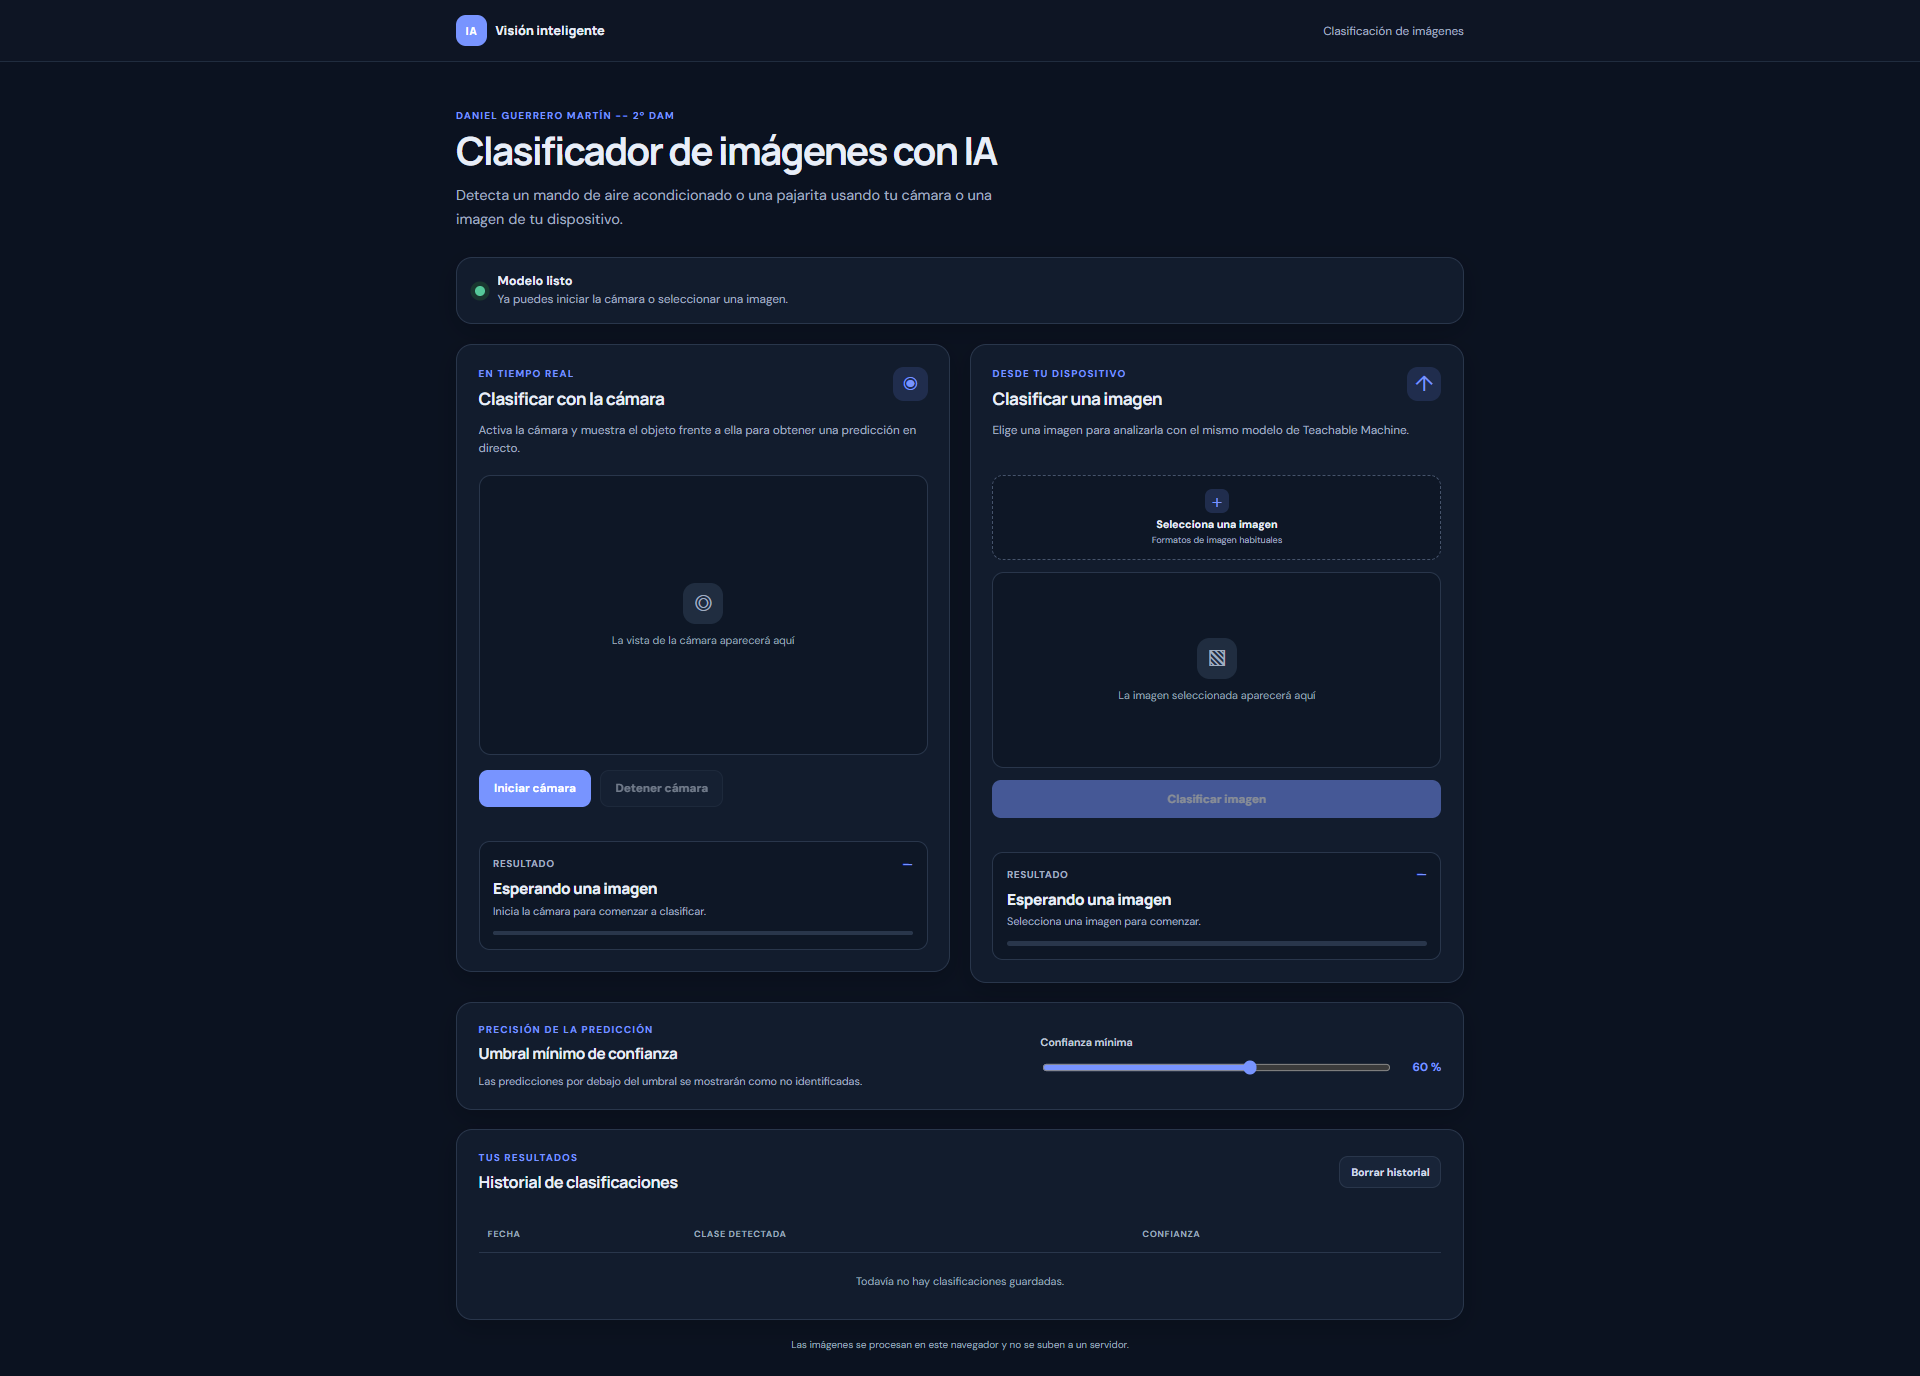

Prueba con mando de aire acondicionado desde la cámara

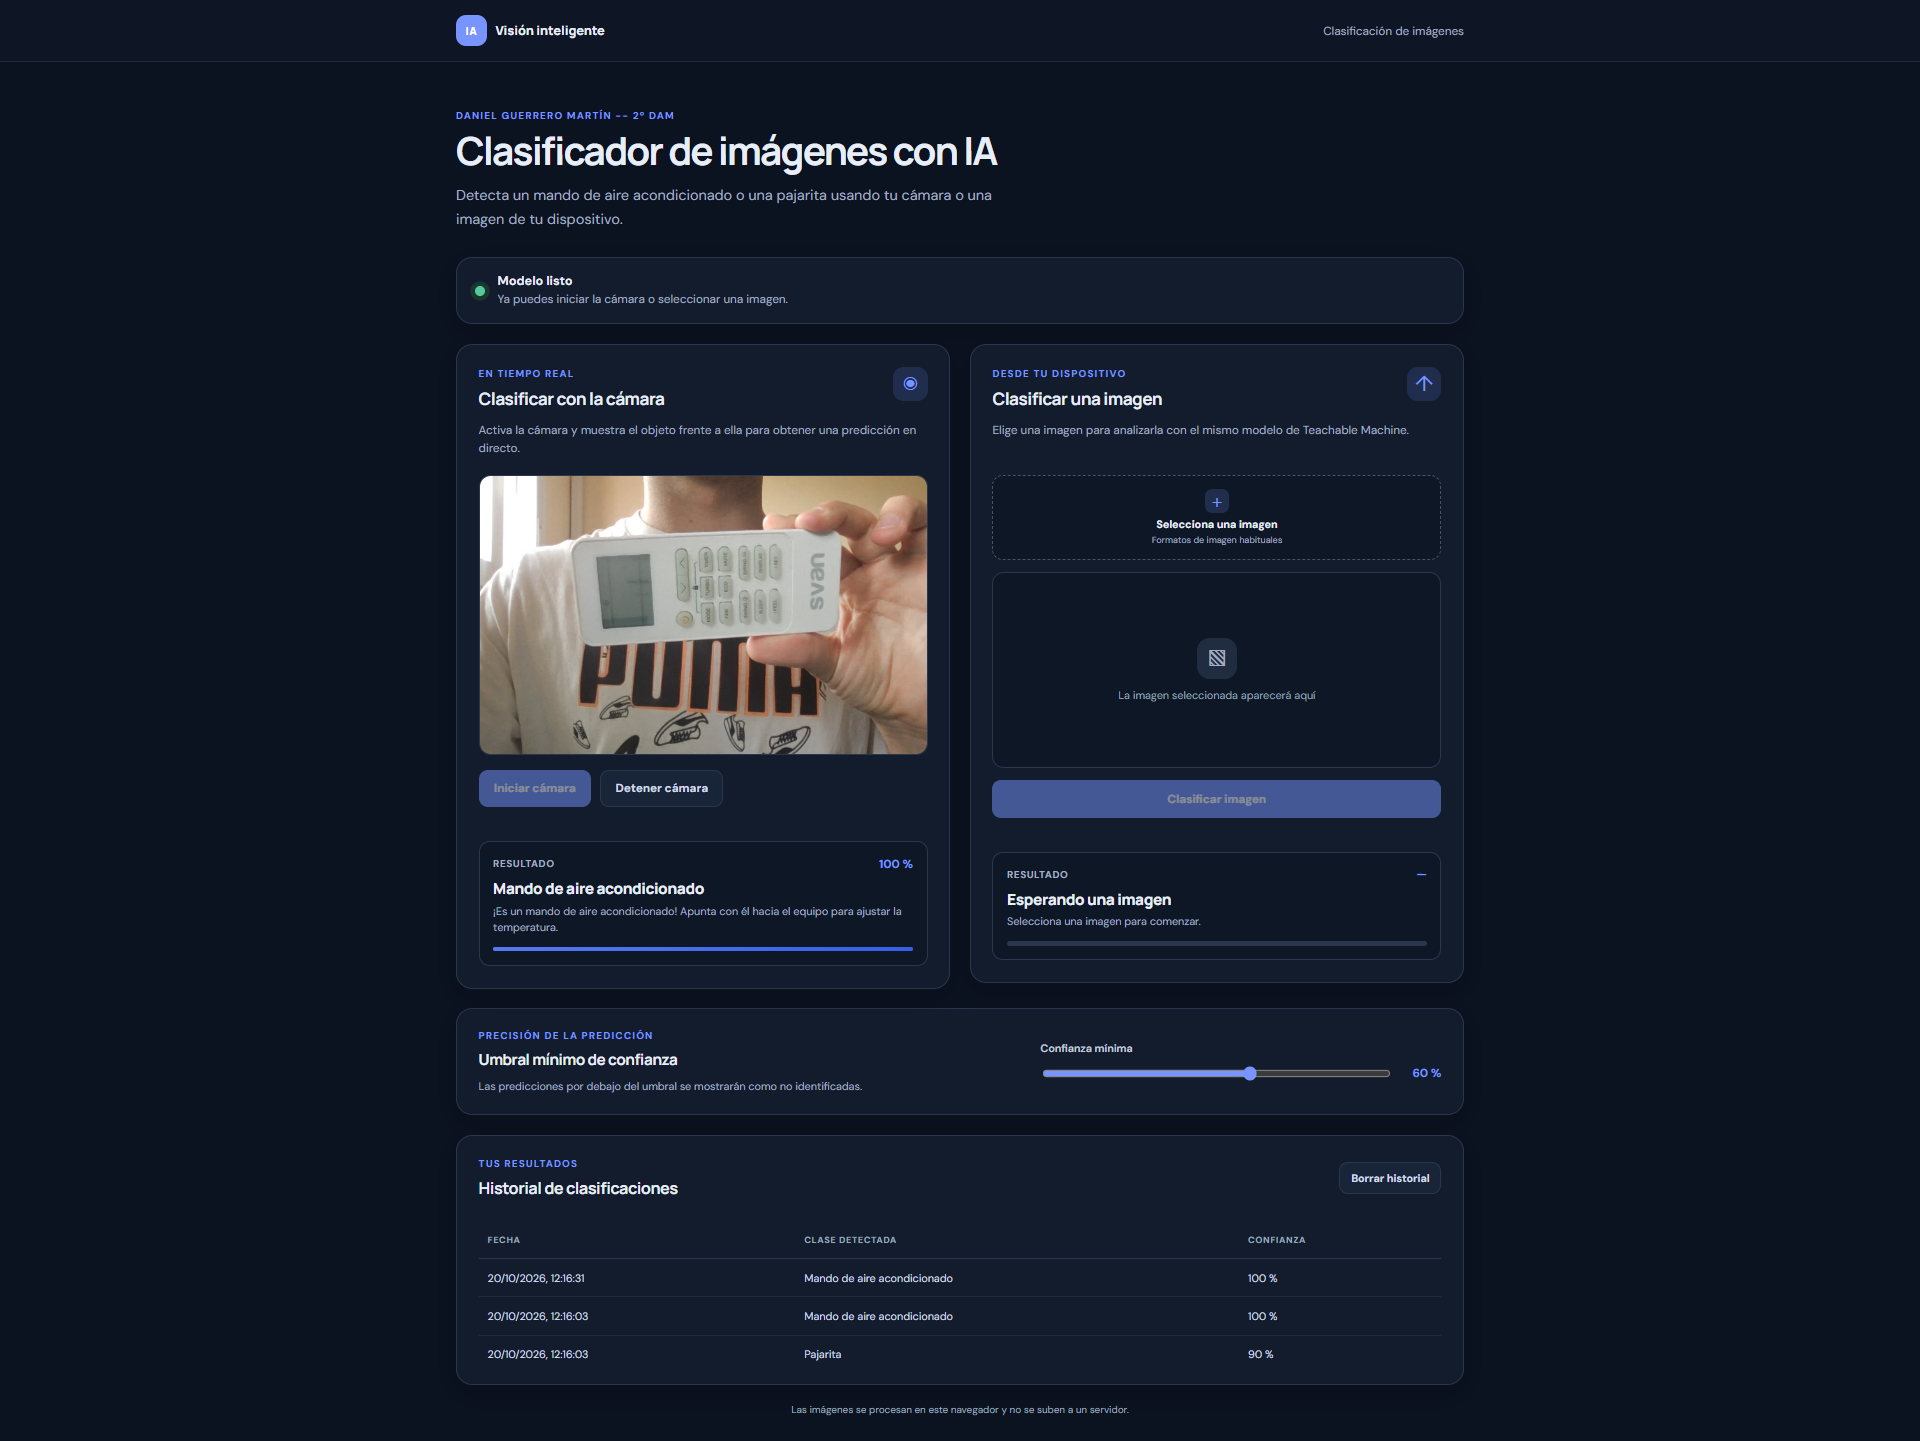

Prueba con pajarita desde la cámara

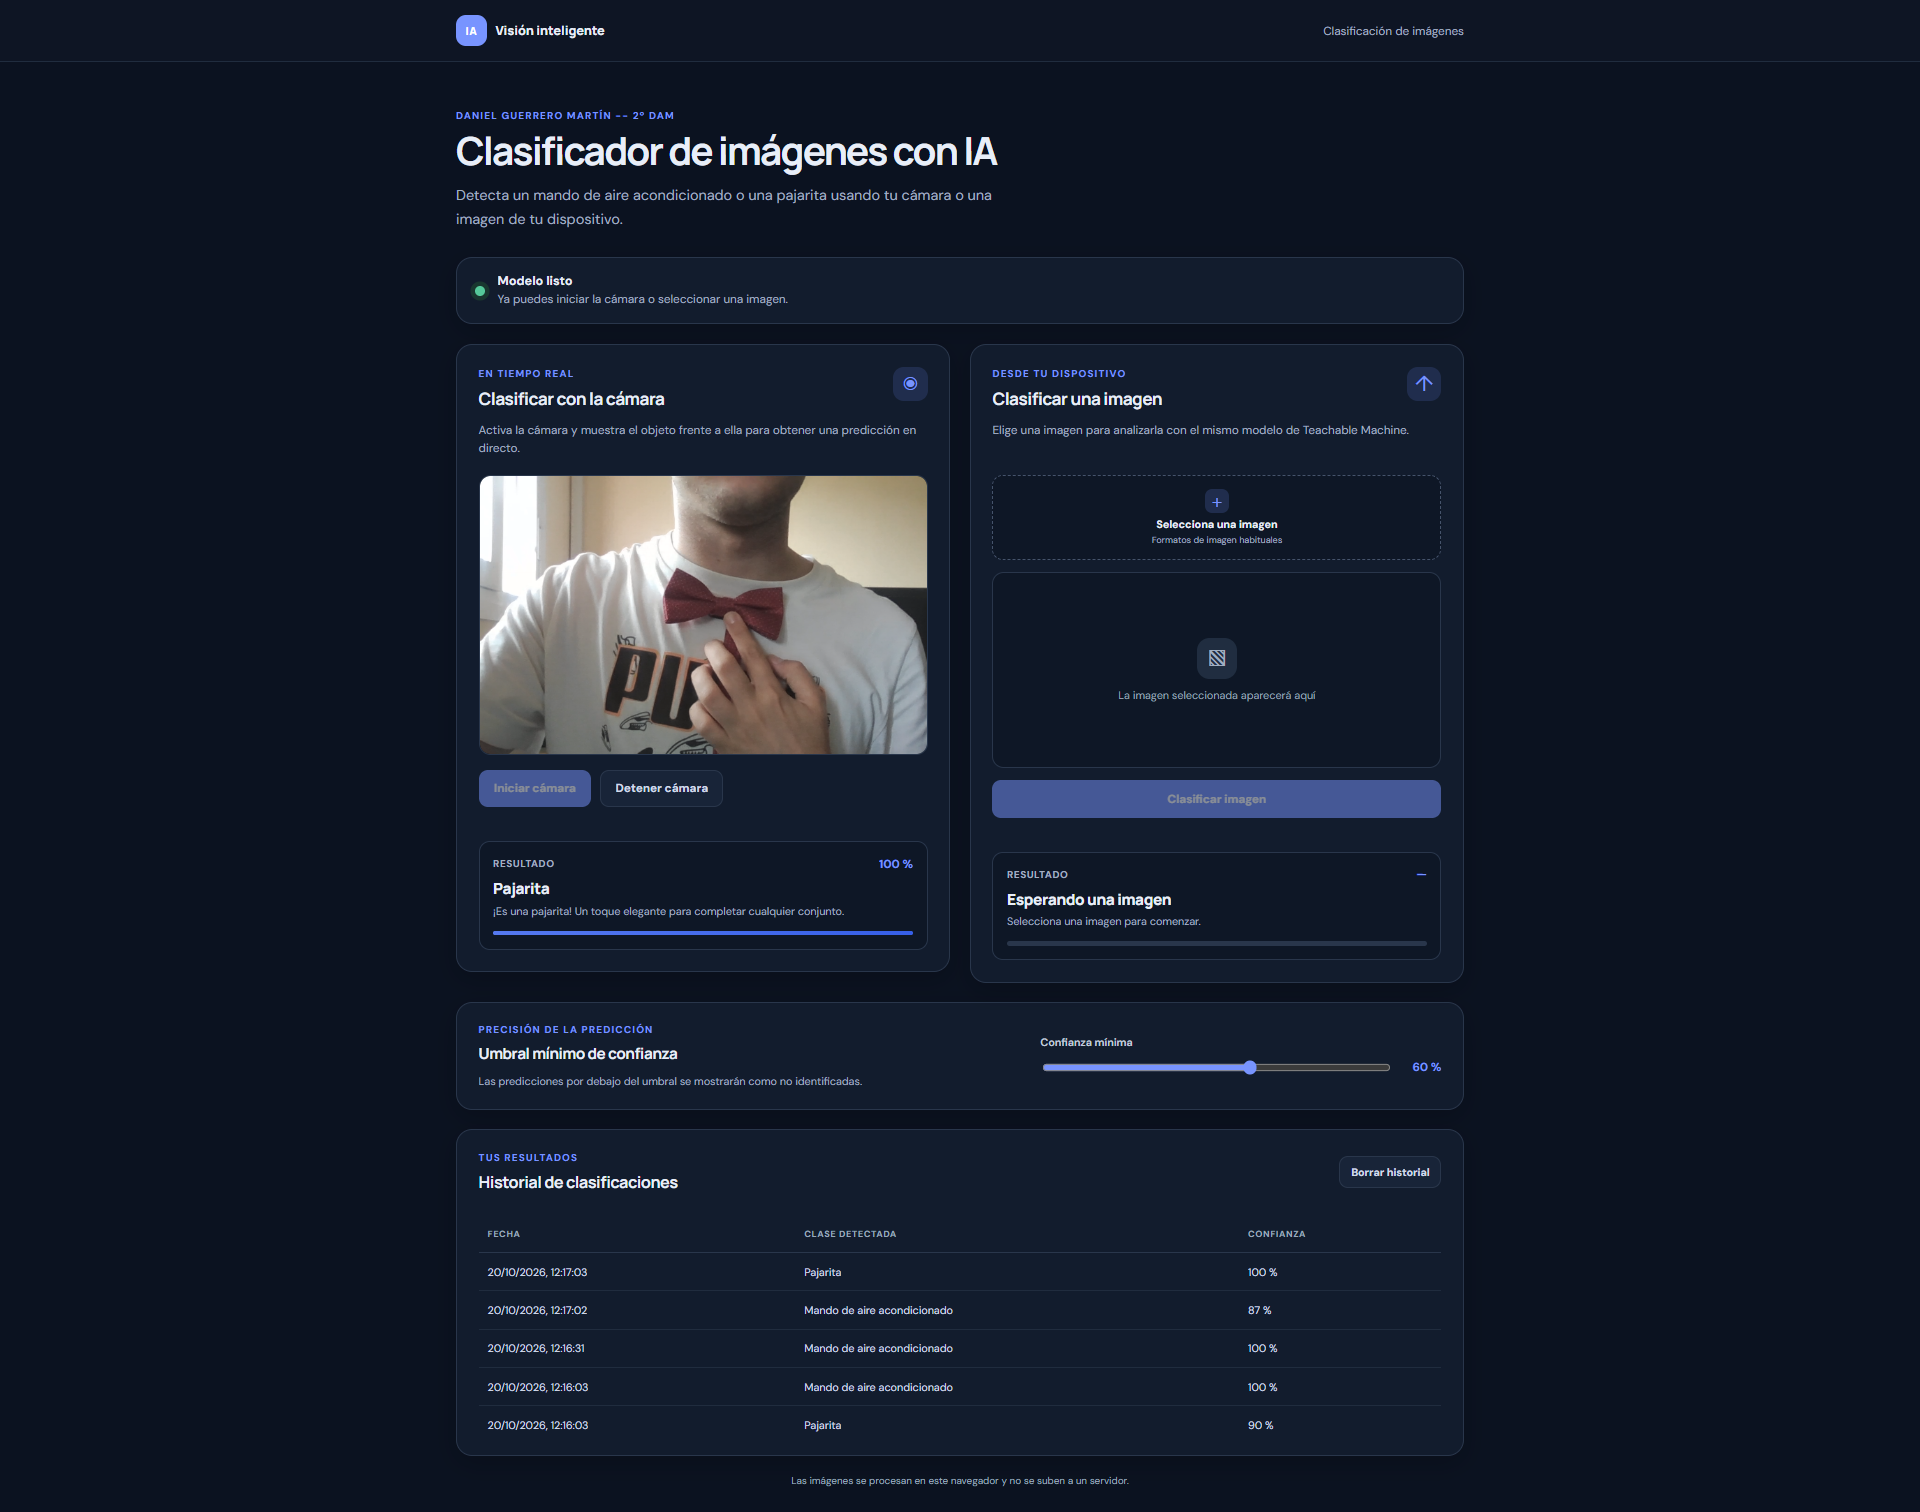

Prueba con mando de aire acondicionado desde una imagen

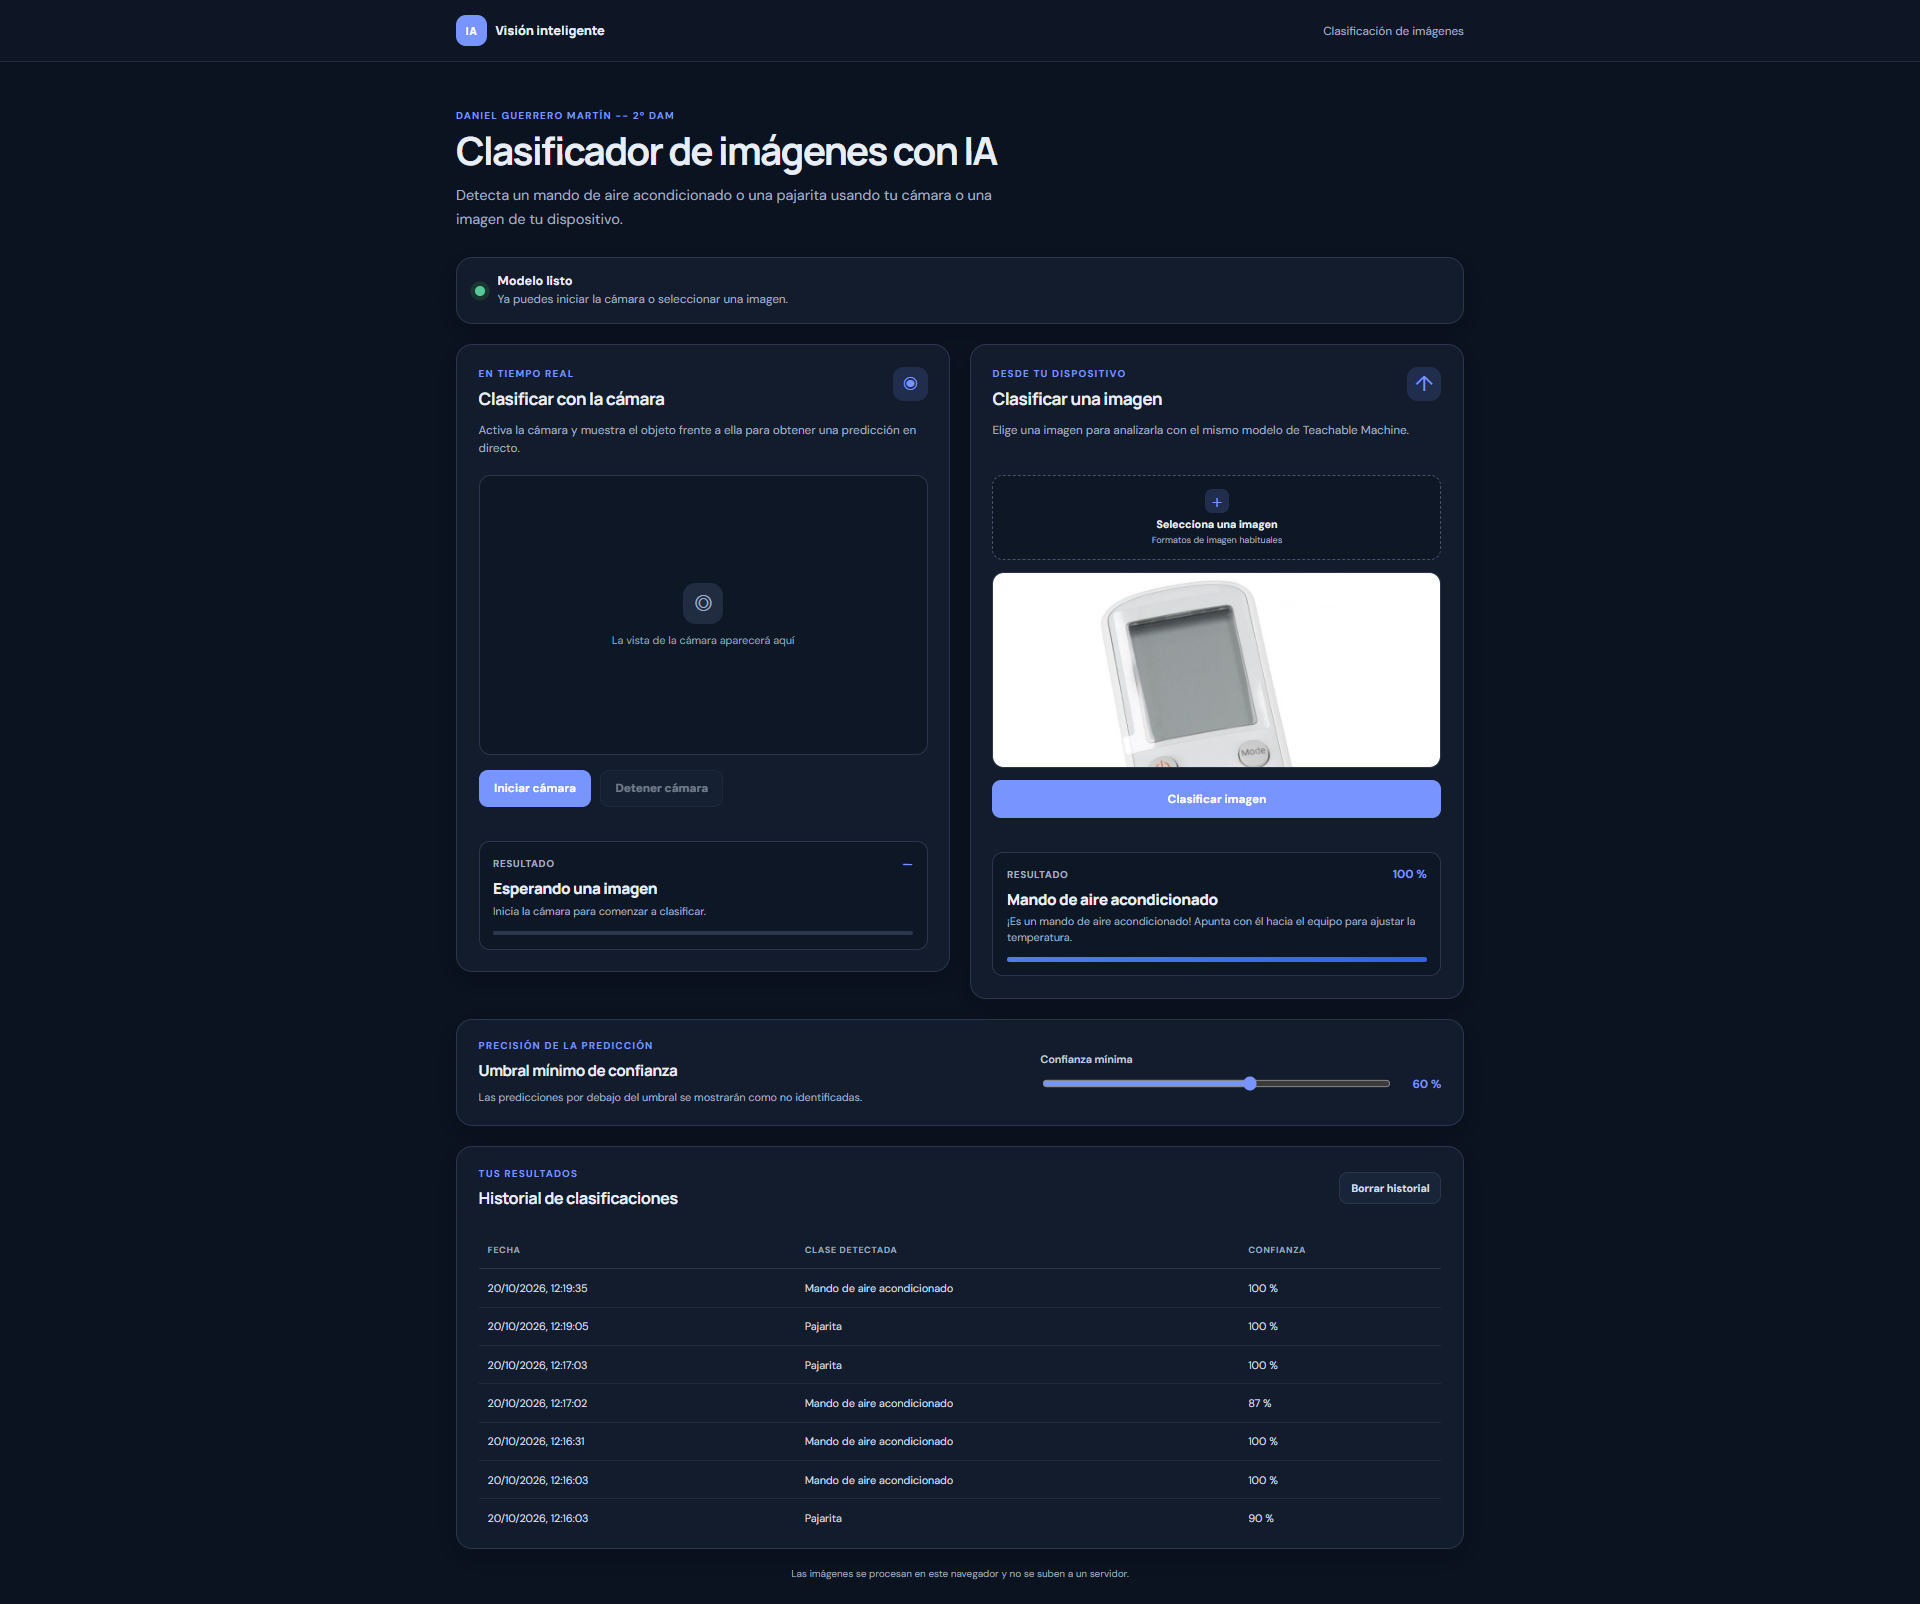

Prueba con pajarita desde una imagen

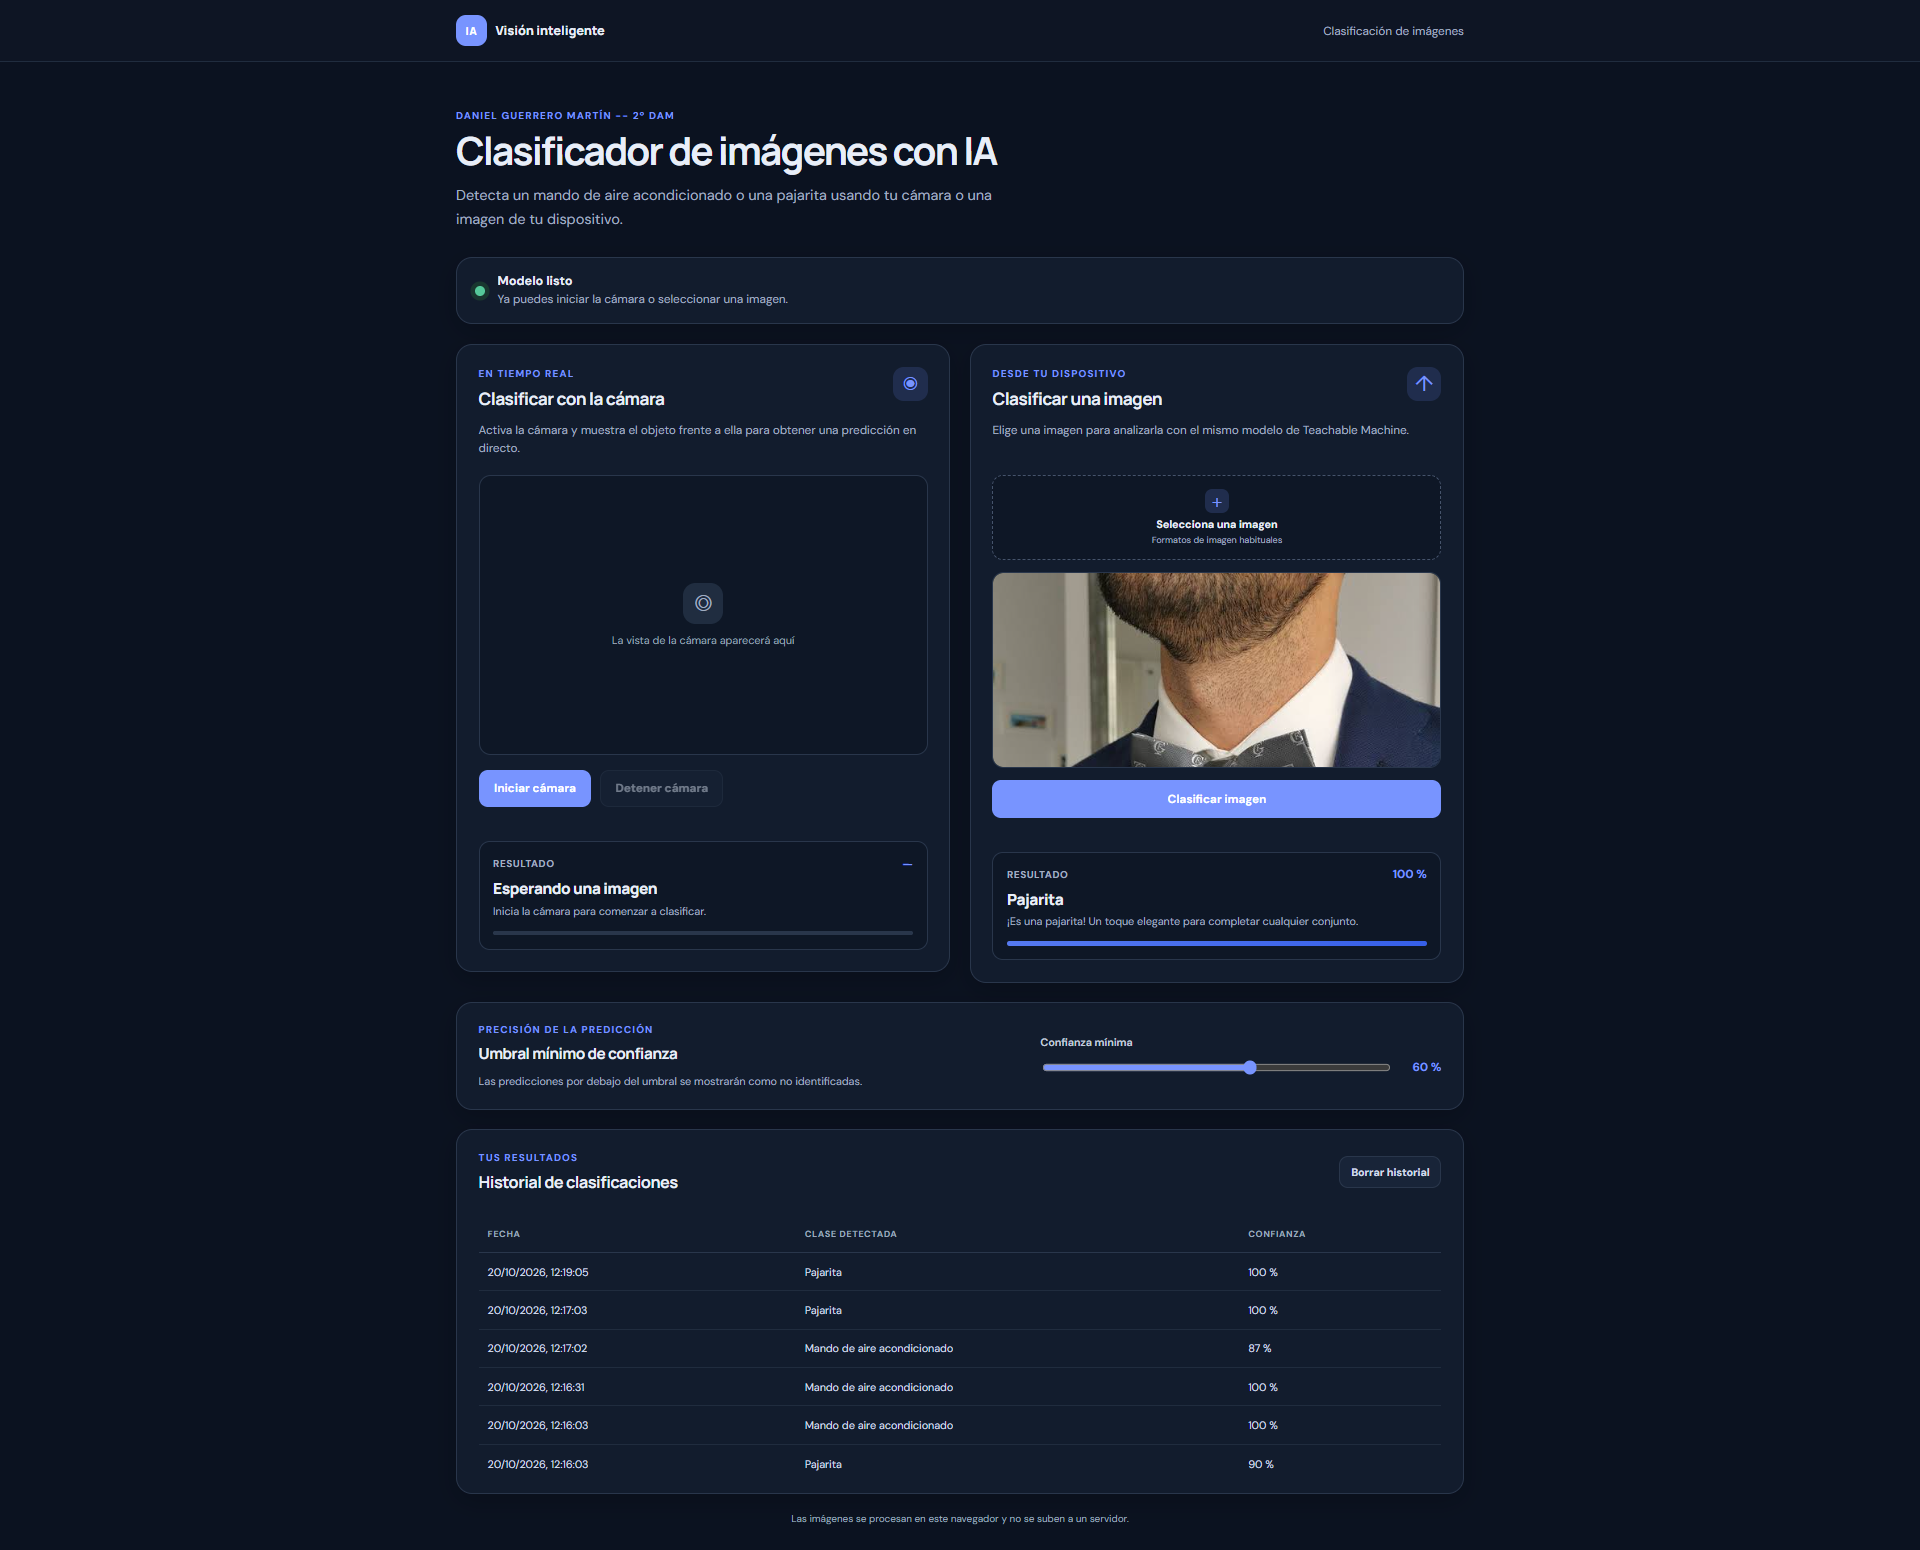

Prueba con otra cosa desde una imagen

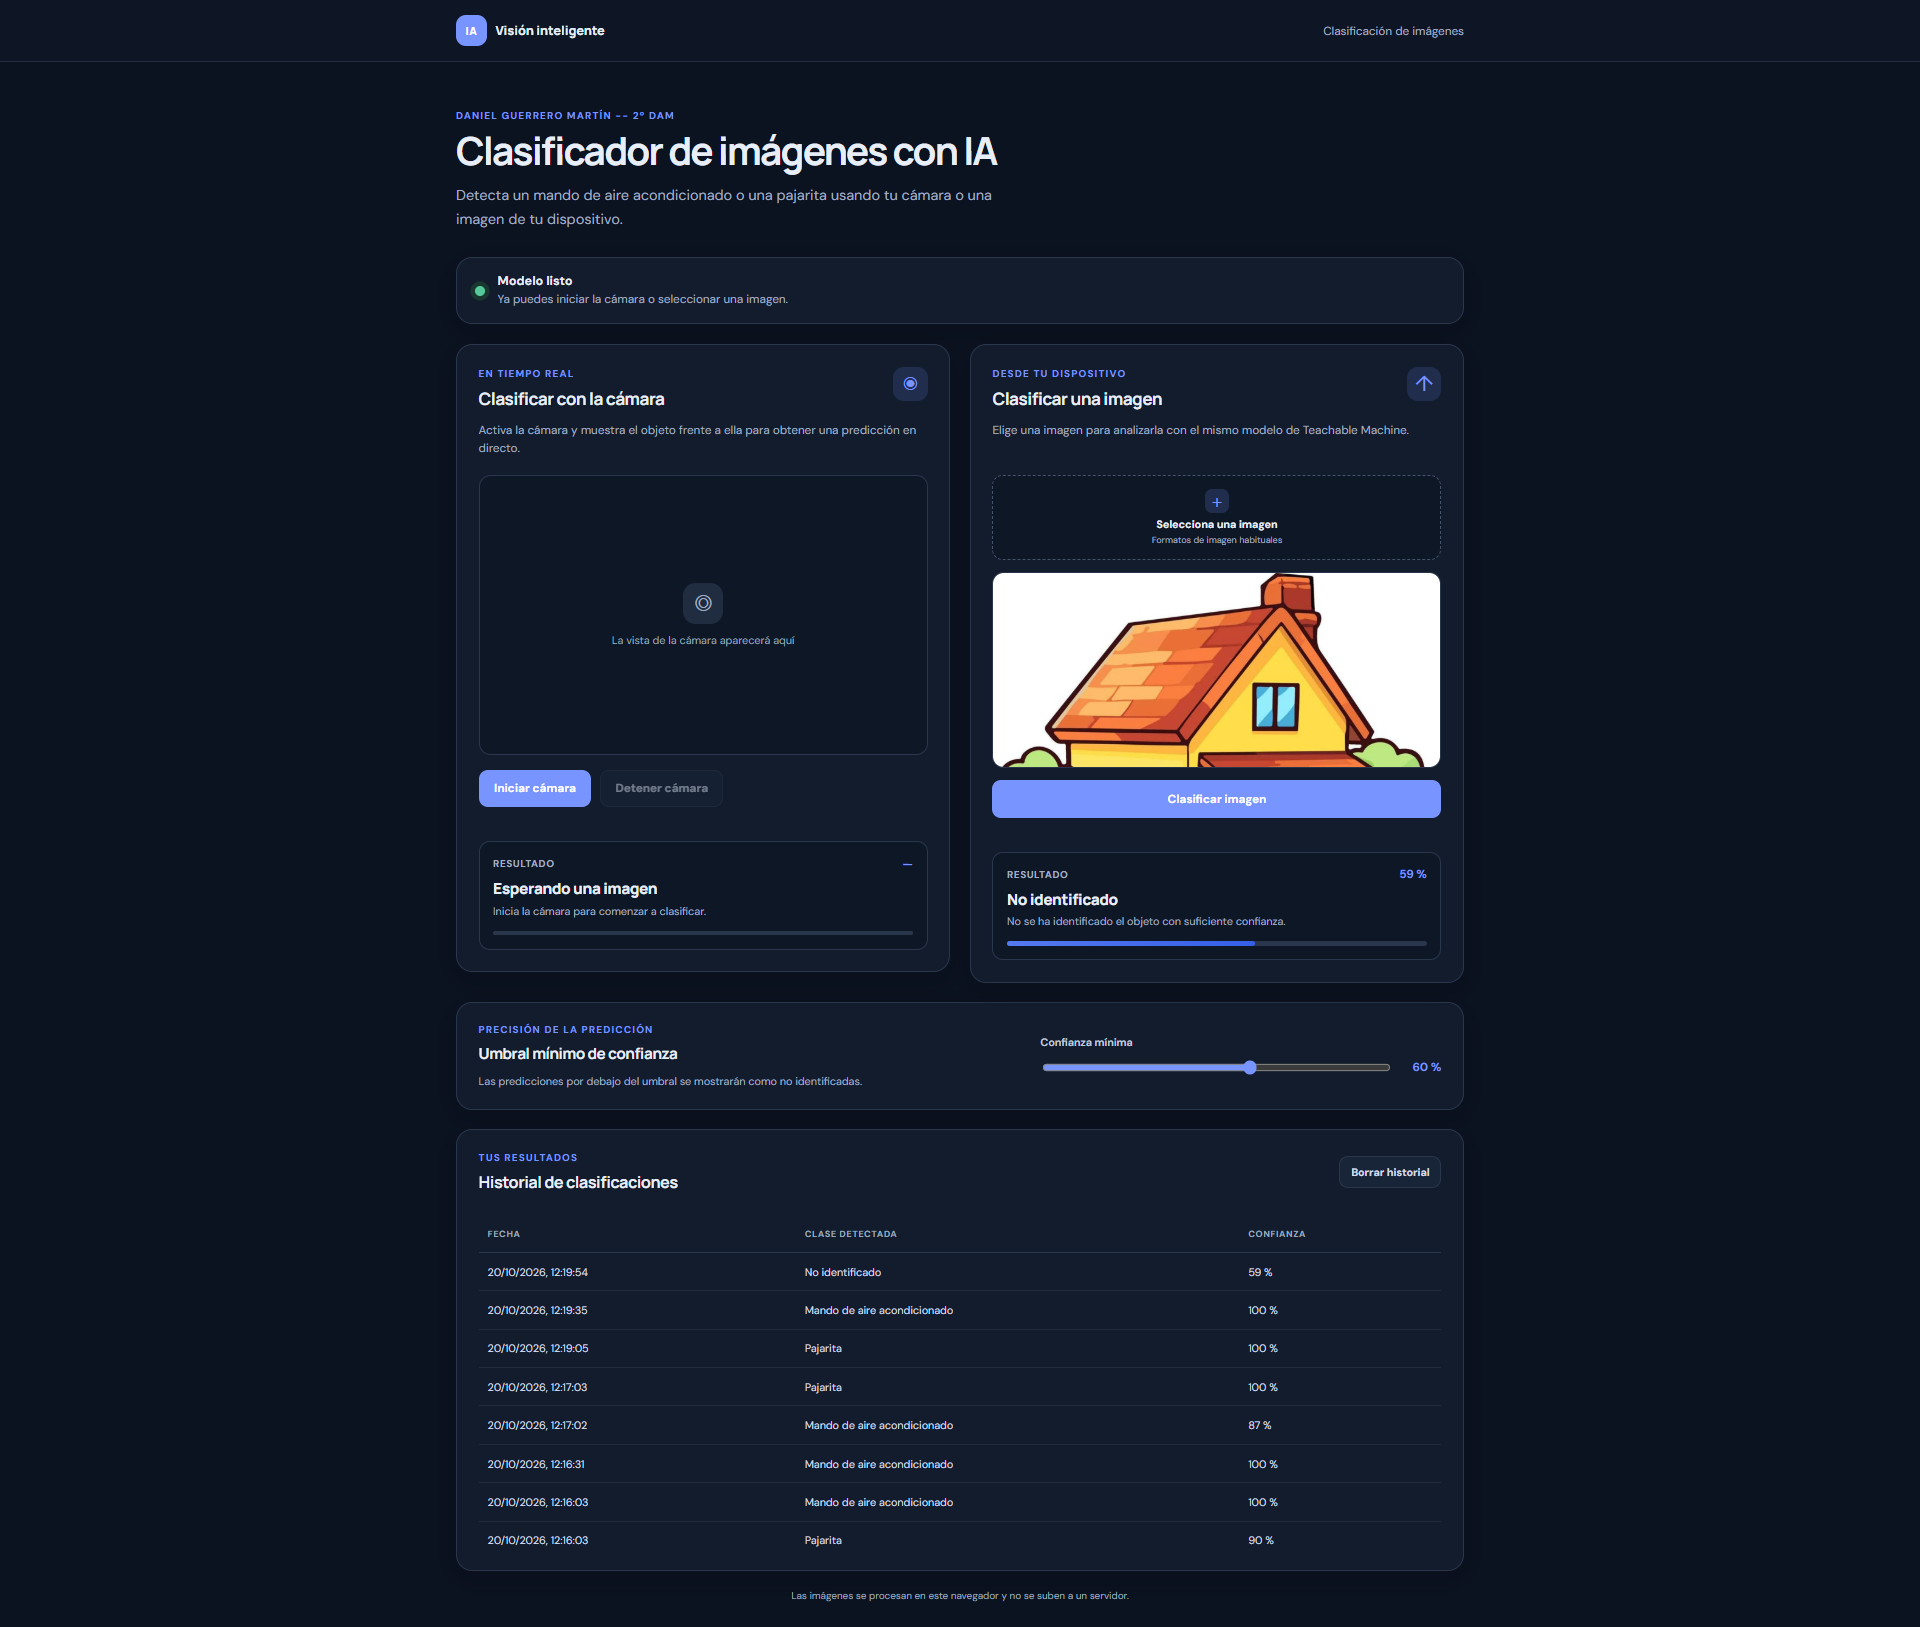